# EntityGuard — Student 3 Notebook
### Statistics, Evaluation, Machine Learning, Error Analysis & Application

**Project:** EntityGuard — Scalable Entity Resolution on the DBLP–Scholar benchmark
**My role (Student 3):** threshold evaluation · precision / recall / F1 · Logistic Regression & Decision Tree · error analysis · scalability results · human-review interface · dashboard

---

**How to run this notebook in Google Colab**

1. `Runtime → Change runtime type → CPU` (no GPU needed).
2. Put `DBLP-Scholar.zip` in your Google Drive in a folder called **`EntityGuard`** (i.e. `My Drive/EntityGuard/DBLP-Scholar.zip`).
   If it is not there, the notebook will ask you to upload it.
3. `Runtime → Run all`. The full run takes roughly **5–10 minutes** on free Colab.
4. All results (CSV tables, plots, SQLite database, review decisions) are saved to `My Drive/EntityGuard/outputs/`, so they survive a Colab disconnect.
5. The last sections start the **web app** (review interface + dashboard). Click the public `gradio.live` link it prints.

**About my teammates' code.** Student 1 (similarity functions) and Student 2 (database & blocking) own those parts of the project. So that this notebook can run end-to-end on its own, Sections 4–7 contain *reference* versions of their components, marked with 🔁. When their modules are ready in the GitHub repo, replace those cells with an import, e.g.

```python
!git clone https://github.com/<team>/entityguard.git
import sys; sys.path.append('entityguard/src')
from similarity import levenshtein, jaccard, ngram_similarity
from blocking import run_blocking
```

As long as their functions return the same shapes (candidate pairs as `(dblp_id, scholar_id)`, similarity scores in `[0, 1]`), all of my sections (8 onwards) work unchanged.

**Important rule from the problem statement:** the `GOLD_MATCH` table is used **only for evaluation** — never to generate predictions. Weights and thresholds are tuned on a *validation* split and reported on a *test* split that is never used for tuning.

## 1. Setup

In [1]:
!pip -q install rapidfuzz gradio

In [2]:
import os, sys, time, re, json, math, random, sqlite3, zipfile, glob, shutil, string, unicodedata, itertools, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein as RFLevenshtein

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
random.seed(SEED); np.random.seed(SEED)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/EntityGuard"
else:
    BASE = os.environ.get("EG_BASE", os.path.abspath("EntityGuard"))

DATA_DIR = f"{BASE}/data"
OUT_DIR = f"{BASE}/outputs"
for d in (BASE, DATA_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

# SQLite works best on the local Colab disk; we copy it to Drive at the end.
DB_PATH = "/content/entityguard.db" if IN_COLAB else f"{BASE}/entityguard.db"
REVIEW_CSV = f"{OUT_DIR}/human_reviews.csv"   # review decisions are also appended here (persistent)

def save_fig(fig, name):
    path = f"{OUT_DIR}/{name}.png"
    fig.savefig(path, bbox_inches="tight", dpi=150)
    return path

print("Running in Colab:", IN_COLAB)
print("Project folder  :", BASE)

Mounted at /content/drive
Running in Colab: True
Project folder  : /content/drive/MyDrive/EntityGuard


## 2. Get the dataset

The notebook looks for the three CSV files in `EntityGuard/data/`. If they are missing it unzips `DBLP-Scholar.zip` from the `EntityGuard` folder (or from `/content`), and if that is missing too it opens an upload dialog.

In [3]:
FILES = ["DBLP1.csv", "Scholar.csv", "DBLP-Scholar_perfectMapping.csv"]

def have_files():
    return all(os.path.exists(f"{DATA_DIR}/{f}") for f in FILES)

def extract_zip(zpath):
    with zipfile.ZipFile(zpath) as z:
        z.extractall(DATA_DIR)
    # files may sit inside a sub-folder of the zip -> move them up
    for root, _, names in os.walk(DATA_DIR):
        for n in names:
            if n in FILES and root != DATA_DIR:
                shutil.move(os.path.join(root, n), os.path.join(DATA_DIR, n))

if not have_files():
    zips = [p for p in glob.glob(f"{BASE}/*.zip") + glob.glob("/content/*.zip") if "scholar" in p.lower()]
    if not zips and IN_COLAB:
        from google.colab import files
        print("Please upload DBLP-Scholar.zip")
        uploaded = files.upload()
        for name, content in uploaded.items():
            with open(f"{BASE}/{name}", "wb") as f:
                f.write(content)
            zips.append(f"{BASE}/{name}")
    for z in zips:
        extract_zip(z)

assert have_files(), f"Dataset not found. Put DBLP-Scholar.zip into {BASE}"
print("Dataset files:", os.listdir(DATA_DIR))

Dataset files: ['Scholar.csv', 'DBLP1.csv', 'DBLP-Scholar_perfectMapping.csv']


## 3. Load data & initial dataset analysis (Section 10 of the problem statement)

⚠️ The two files use **different text encodings**: `DBLP1.csv` is Latin-1 and `Scholar.csv` is UTF-8 with a BOM. Reading both the same way breaks names such as *Wäsch*.

In [4]:
dblp = pd.read_csv(f"{DATA_DIR}/DBLP1.csv", encoding="latin-1")
scholar = pd.read_csv(f"{DATA_DIR}/Scholar.csv", encoding="utf-8-sig")
gold_df = pd.read_csv(f"{DATA_DIR}/DBLP-Scholar_perfectMapping.csv").rename(
    columns={"idDBLP": "dblp_id", "idScholar": "scholar_id"})

for df in (dblp, scholar):
    df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
    for c in ("title", "authors", "venue"):
        df[c] = df[c].where(df[c].notna() & (df[c].astype(str).str.strip() != ""), None)

N_D, N_S = len(dblp), len(scholar)
P_ALL = N_D * N_S
GOLD = set(zip(gold_df.dblp_id, gold_df.scholar_id))
print(f"DBLP records    : {N_D:,}")
print(f"Scholar records : {N_S:,}")
print(f"Gold matches    : {len(GOLD):,}")
print(f"Cartesian pairs : {P_ALL:,}")
dblp.head(3)

DBLP records    : 2,616
Scholar records : 64,263
Gold matches    : 5,347
Cartesian pairs : 168,112,008


,id,title,authors,venue,year
0,conf/vldb/RusinkiewiczKTWM95,Towards a Cooperative Transaction Model - The Cooperative Activity Model,"M Rusinkiewicz, W Klas, T Tesch, J Wäsch, P Muth",VLDB,1995
1,journals/sigmod/EisenbergM02,SQL/XML is Making Good Progress,"A Eisenberg, J Melton",SIGMOD Record,2002
2,conf/vldb/AmmannJR95,Using Formal Methods to Reason about Semantics-Based Decompositions of Trans...,"P Ammann, S Jajodia, I Ray",VLDB,1995


In [5]:
def profile(df, name):
    t = df["title"].fillna("")
    a = df["authors"].fillna("")
    return {
        "source": name,
        "records": len(df),
        "missing title": int(df.title.isna().sum()),
        "missing authors": int(df.authors.isna().sum()),
        "missing venue": int(df.venue.isna().sum()),
        "missing year": int(df.year.isna().sum()),
        "missing year %": round(100 * df.year.isna().mean(), 1),
        "unique years": int(df.year.nunique()),
        "year range": f"{df.year.min()}–{df.year.max()}",
        "avg title length (chars)": round(t.str.len().mean(), 1),
        "avg title length (words)": round(t.str.split().str.len().mean(), 1),
        "avg authors per record": round(a[a != ""].str.split(",").str.len().mean(), 2),
        "duplicate IDs": int(df.id.duplicated().sum()),
    }

stats_df = pd.DataFrame([profile(dblp, "DBLP"), profile(scholar, "Scholar")]).set_index("source").T
stats_df.to_csv(f"{OUT_DIR}/dataset_statistics.csv")
stats_df

source,DBLP,Scholar
records,2616,64263
missing title,0,0
missing authors,218,1
missing venue,211,14997
missing year,0,34790
missing year %,0.0,54.1
unique years,10,127
year range,1994–2003,11–2730
avg title length (chars),56.4,60.6
avg title length (words),7.5,8.1


In [6]:
def punct_freq(series):
    c = Counter(ch for s in series.dropna() for ch in s if ch in string.punctuation)
    return c

pf = pd.DataFrame({"DBLP": punct_freq(dblp.title), "Scholar": punct_freq(scholar.title)}).fillna(0).astype(int)
pf["DBLP per 100 titles"] = (100 * pf.DBLP / N_D).round(1)
pf["Scholar per 100 titles"] = (100 * pf.Scholar / N_S).round(1)
punct_df = pf.sort_values("Scholar", ascending=False).head(12)
punct_df.to_csv(f"{OUT_DIR}/punctuation_frequency.csv")
print("Punctuation in titles")
punct_df

Punctuation in titles


,DBLP,Scholar,DBLP per 100 titles,Scholar per 100 titles
-,994,19821,38.0,30.8
:,692,14142,26.5,22.0
",",241,13894,9.2,21.6
.,27,11312,1.0,17.6
?,50,8776,1.9,13.7
(,98,3091,3.7,4.8
),98,2872,3.7,4.5
;,2,1885,0.1,2.9
&,6,1505,0.2,2.3
',134,1482,5.1,2.3


In [7]:
venues_df = pd.concat([
    dblp.venue.value_counts().head(10).rename_axis("DBLP venue").reset_index(name="DBLP count"),
    scholar.venue.value_counts().head(10).rename_axis("Scholar venue").reset_index(name="Scholar count")], axis=1)
venues_df.to_csv(f"{OUT_DIR}/common_venues.csv", index=False)
venues_df

,DBLP venue,DBLP count,Scholar venue,Scholar count
0,VLDB,861.0,"LECTURE NOTES IN COMPUTER SCIENCE,",964
1,SIGMOD Conference,771.0,"Cochrane Database Syst Rev,",910
2,SIGMOD Record,449.0,"New Directions for Higher Education,",894
3,VLDB J.,191.0,"Phil. Mag,",832
4,ACM Trans. Database Syst.,132.0,"Computer Networks,",796
5,ecord,1.0,"BT Technology Journal,",751
6,NaN,NaN,"VLDB,",741
7,NaN,NaN,"SIGMOD Record,",738
8,NaN,NaN,"Information and Software Technology,",690
9,NaN,NaN,"ACM Transactions on Database Systems,",685


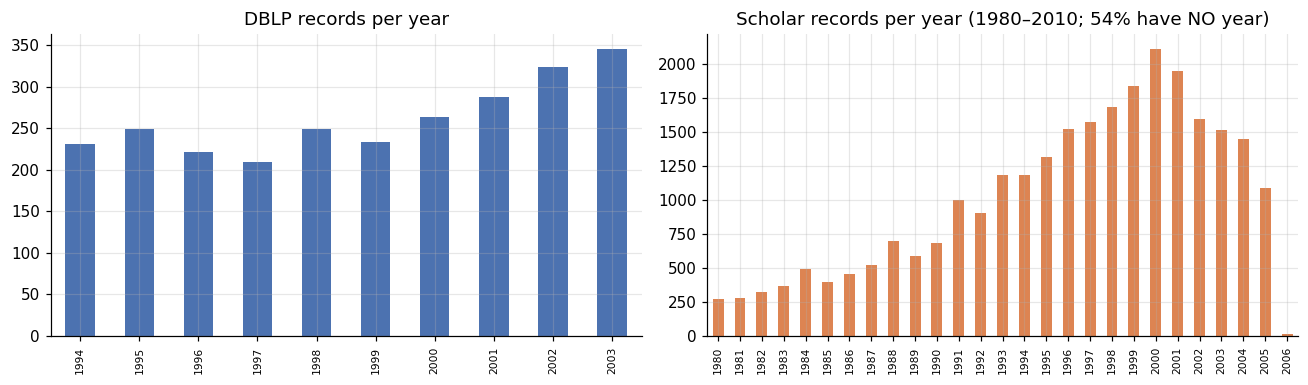

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
dblp.year.value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#4C72B0")
ax[0].set_title("DBLP records per year"); ax[0].set_xlabel("")
sy = scholar.year.dropna()
sy[(sy >= 1980) & (sy <= 2010)].value_counts().sort_index().plot(kind="bar", ax=ax[1], color="#DD8452")
ax[1].set_title(f"Scholar records per year (1980–2010; {scholar.year.isna().mean():.0%} have NO year)")
ax[1].set_xlabel("")
for a in ax:
    a.tick_params(axis="x", labelsize=7)
plt.tight_layout(); save_fig(fig, "year_distribution"); plt.show()

### 3.1 Inspecting the gold mapping

Key facts that shape the evaluation design:
- the mapping is **many-to-many** — one DBLP paper can match several Scholar records (Scholar often has duplicates of the same paper), so we must **not** force a 1-to-1 assignment;
- we check how often the gold pairs agree on year / exact title, which tells us how much weight those attributes deserve.

In [9]:
dd = dblp.set_index("id"); ss = scholar.set_index("id")
g = gold_df.copy()
g["d_year"] = g.dblp_id.map(dd.year); g["s_year"] = g.scholar_id.map(ss.year)
per_dblp = g.groupby("dblp_id").size()

gold_facts = {
    "gold pairs": len(g),
    "distinct DBLP ids in gold": g.dblp_id.nunique(),
    "distinct Scholar ids in gold": g.scholar_id.nunique(),
    "DBLP records with >1 Scholar match": int((per_dblp > 1).sum()),
    "max Scholar matches for one DBLP record": int(per_dblp.max()),
    "DBLP records with NO gold match": N_D - g.dblp_id.nunique(),
    "gold pairs: same year": int((g.d_year == g.s_year).sum()),
    "gold pairs: year differs": int(((g.d_year != g.s_year) & g.s_year.notna()).sum()),
    "gold pairs: Scholar year missing": int(g.s_year.isna().sum()),
}
pd.Series(gold_facts, name="value").to_frame()

,value
gold pairs,5347
distinct DBLP ids in gold,2408
distinct Scholar ids in gold,5218
DBLP records with >1 Scholar match,1238
max Scholar matches for one DBLP record,20
DBLP records with NO gold match,208
gold pairs: same year,2424
gold pairs: year differs,157
gold pairs: Scholar year missing,2766


In [10]:
sample = g.sample(8, random_state=SEED)
pd.DataFrame({
    "DBLP title": sample.dblp_id.map(dd.title).values,
    "Scholar title": sample.scholar_id.map(ss.title).values,
    "DBLP authors": sample.dblp_id.map(dd.authors).values,
    "Scholar authors": sample.scholar_id.map(ss.authors).values,
    "DBLP venue": sample.dblp_id.map(dd.venue).values,
    "Scholar venue": sample.scholar_id.map(ss.venue).values,
})

,DBLP title,Scholar title,DBLP authors,Scholar authors,DBLP venue,Scholar venue
0,Fast Nearest Neighbor Search in Medical Image Databases,"Fast nearest neighbor search in medical image databases, University of Maryl...","F Korn, N Sidiropoulos, C Faloutsos, E Siegel, Z Protopapas","F Korn, N Sidiropoulos, C Faloutsos, E Siegel, Z",VLDB,"MD,"
1,SPRINT: A Scalable Parallel Classifier for Data Mining,SPRINT: A scalable parallel classifier for data mining,"J Shafer, R Agrawal, M Mehta","CS John, R AGRAWAL, M MEHTA",VLDB,"Proc. 22nd Int. Conf. Very Large Databases,"
2,Data Warehousing and OLAP for Decision Support (Tutorial),Data warehousing and OLAP for decision support,None,"S Chaudhuri, U Dayal",None,"Proceedings of the 1997 ACM SIGMOD international conference &hellip;,"
3,The Third Manifesto,Introducing The Third Manifesto,"H Darwen, C Date","H Darwen, CJ Date",SIGMOD Record,"DATABASE PROGRAMMING AND DESIGN,"
4,Efficacious Data Cube Exploration by Semantic Summarization and Compression,Efficacious Data Cube Exploration by Semantic Summarization and Compression,"L Lakshmanan, J Pei, Y Zhao","LVS Lakshmanan, J Pei, Y Zhao",VLDB,"VLDB,"
5,The Aqua Approximate Query Answering System,The AQUA approximate query answering system. SIGMOD 1999,"S Acharya, P Gibbons, V Poosala, S Ramaswamy","S Acharya, PB Gibbons, V Poosala, S Ramaswamy",SIGMOD Conference,"Proceedings ACM SIGMOD International Conference on &hellip;,"
6,"Object-Relational Database Systems: Principles, Products, and Challenges (Tu...","Object-Relational Database Systems-Principles, Products and Challenges",None,"K Kulkarni, N Mattos, A Nori",None,None
7,Implementing Data Cubes Efficiently,Rajaraman. A. Implementing data cubes efficiently,"V Harinarayan, A Rajaraman, J Ullman",UJD Harinarayan,SIGMOD Conference,"Proc ACM SIGMOD Int&#39;l Conf on Management of Data. Montreal,"


**What manual inspection shows:** Scholar years contain impossible values (e.g. 11 or 2730) as well as being missing for 54 % of records. Scholar titles are often noisy — words glued together (`TheGlue-Naildeductivedatabasesystem`), author names or citation text prepended (`Ranganathan., M. and ... (1994) Fast subsequence matching...`), broken encodings (`â??`) and ligature damage (`E. cient` for *Efficient*). Scholar venues are frequently missing or abbreviated. These observations motivate character n-gram features and make error analysis (Section 15) meaningful.

## 4. 🔁 Normalization (Student 1's component — reference version)

In [11]:
STOP_WORDS = {"a", "an", "the", "of", "for", "and", "in", "on", "to", "with", "by", "from",
              "at", "as", "is", "are", "its", "into", "via", "using", "based", "towards", "toward"}
VENUE_STOP = STOP_WORDS | {"proc", "proceedings", "conf", "conference", "international", "intl",
                           "annual", "symposium", "workshop", "acm", "ieee", "th", "st", "nd", "rd"}

def normalize_text(s):
    """lowercase, strip accents & broken encodings, punctuation -> space, collapse whitespace"""
    if s is None or (isinstance(s, float) and math.isnan(s)):
        return ""
    s = re.sub(r"â[^\w\s]*", " ", str(s))           # mojibake such as 'â??'
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    s = re.sub(r"[^a-z0-9]+", " ", s.lower())
    return " ".join(s.split())

def title_tokens(s):
    return [t for t in normalize_text(s).split() if t not in STOP_WORDS]

def normalize_title(s):
    return " ".join(title_tokens(s))

def author_names(s):
    """'M Rusinkiewicz, W Klas' -> ['m rusinkiewicz', 'w klas'] (order is NOT assumed to match)"""
    if not s:
        return []
    parts = re.split(r",|;|\band\b", str(s))
    names = [normalize_text(p) for p in parts]
    return [n for n in names if n]

def last_name(name):
    toks = name.split()
    long = [t for t in toks if len(t) > 1]
    return long[-1] if long else toks[-1]

def venue_tokens(s):
    """venue tokens without generic words, plus an acronym ('international conference on data engineering' -> 'icde')"""
    raw = [t for t in normalize_text(s).split() if not t.isdigit()]
    toks = [t for t in raw if t not in VENUE_STOP]
    acr_words = [t for t in raw if t not in STOP_WORDS and t not in {"proc", "proceedings", "th"}]
    acr = "".join(t[0] for t in acr_words) if len(acr_words) >= 2 else ""
    return toks + ([acr] if acr else [])

print(normalize_title("An Efficient Method for Record-Linkage!"))
print(author_names("Smith, J.; Kumar, A."), "|", author_names("M Rusinkiewicz, W Klas, J Wäsch"))
print(venue_tokens("International Conference on Data Engineering"), venue_tokens("Proc. ICDE"))

efficient method record linkage
['smith', 'j', 'kumar', 'a'] | ['m rusinkiewicz', 'w klas', 'j wasch']
['data', 'engineering', 'icde'] ['icde']


In [12]:
def add_normalized_columns(df):
    df["t_tokens"] = df.title.map(title_tokens)
    df["t_norm"] = df.t_tokens.map(" ".join)
    df["t_squash"] = df.t_tokens.map("".join)          # robust to glued words in Scholar titles
    df["a_names"] = df.authors.map(author_names)
    df["a_tokens"] = df.a_names.map(lambda ns: sorted({t for n in ns for t in n.split()}))
    df["a_last"] = df.a_names.map(lambda ns: sorted({last_name(n) for n in ns}))
    df["v_tokens"] = df.venue.map(venue_tokens)
    df["v_squash"] = df.v_tokens.map(lambda t: "".join(t[:-1]) if len(t) > 1 else "".join(t))
    df["yr"] = df.year.astype("float")                   # NaN = missing
    return df

t0 = time.time()
dblp = add_normalized_columns(dblp)
scholar = add_normalized_columns(scholar)
D_IDX = {i: k for k, i in enumerate(dblp.id)}            # id -> row position
S_IDX = {i: k for k, i in enumerate(scholar.id)}
print(f"normalized both sources in {time.time()-t0:.1f}s")
dblp[["title", "t_norm", "a_names", "a_last", "v_tokens"]].head(3)

normalized both sources in 7.6s


,title,t_norm,a_names,a_last,v_tokens
0,Towards a Cooperative Transaction Model - The Cooperative Activity Model,cooperative transaction model cooperative activity model,"[m rusinkiewicz, w klas, t tesch, j wasch, p muth]","[klas, muth, rusinkiewicz, tesch, wasch]",[vldb]
1,SQL/XML is Making Good Progress,sql xml making good progress,"[a eisenberg, j melton]","[eisenberg, melton]","[sigmod, record, sr]"
2,Using Formal Methods to Reason about Semantics-Based Decompositions of Trans...,formal methods reason about semantics decompositions transactions,"[p ammann, s jajodia, i ray]","[ammann, jajodia, ray]",[vldb]


## 5. 🔁 Similarity functions (Student 1's component — reference version)

Reference (pure-Python) implementations exactly as in Sections 15–19 of the problem statement, plus fast vectorized versions used for scoring hundreds of thousands of pairs. A test cell checks that both give identical results.

In [13]:
def levenshtein(a, b):
    """Dynamic-programming edit distance with the two-row memory optimisation: O(mn) time, O(min(m,n)) space."""
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))                       # D(0, j) = j
    for i in range(1, len(a) + 1):
        cur = [i] + [0] * len(b)                         # D(i, 0) = i
        ai = a[i - 1]
        for j in range(1, len(b) + 1):
            c = 0 if ai == b[j - 1] else 1
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + c)
        prev = cur
    return prev[-1]

def edit_similarity(a, b):
    if not a and not b:
        return 1.0
    return 1 - levenshtein(a, b) / max(len(a), len(b))

def jaccard(A, B):
    A, B = set(A), set(B)
    if not A and not B:
        return float("nan")                              # undefined -> treated as missing
    return len(A & B) / len(A | B)

def char_ngrams(s, n):
    return [s[i:i + n] for i in range(len(s) - n + 1)] if len(s) >= n else ([s] if s else [])

def ngram_similarity(a, b, n=3):
    return jaccard(char_ngrams(a, n), char_ngrams(b, n))

def year_similarity(y1, y2):
    if y1 is None or y2 is None or (isinstance(y1, float) and math.isnan(y1)) or (isinstance(y2, float) and math.isnan(y2)):
        return float("nan")
    d = abs(y1 - y2)
    return 1.0 if d == 0 else (0.5 if d == 1 else 0.0)

# --- quick checks against the examples in the problem statement ---
assert levenshtein("kitten", "sitting") == 3
assert jaccard({"deep", "neural", "network", "classification"}, {"neural", "network", "classification"}) == 0.75
assert char_ngrams("database", 2) == ["da", "at", "ta", "ab", "ba", "as", "se"]
assert char_ngrams("database", 3) == ["dat", "ata", "tab", "aba", "bas", "ase"]
assert year_similarity(2005, 2006) == 0.5
print("reference similarity functions OK")

reference similarity functions OK


In [14]:
class SetSpace:
    """Binary sparse matrices so Jaccard can be computed for many pairs at once (same result as jaccard())."""
    def __init__(self, d_lists, s_lists):
        cv = CountVectorizer(analyzer=lambda x: x, binary=True, dtype=np.float32)
        cv.fit(list(d_lists) + list(s_lists))
        self.D = cv.transform(d_lists).tocsr()
        self.S = cv.transform(s_lists).tocsr()
        self.d_size = np.asarray(self.D.sum(1)).ravel()
        self.s_size = np.asarray(self.S.sum(1)).ravel()

    def pairs(self, di, si, chunk=100_000):
        out = np.empty(len(di), dtype=np.float32)
        for k in range(0, len(di), chunk):
            a, b = di[k:k + chunk], si[k:k + chunk]
            inter = np.asarray(self.D[a].multiply(self.S[b]).sum(1)).ravel()
            union = self.d_size[a] + self.s_size[b] - inter
            with np.errstate(invalid="ignore", divide="ignore"):
                out[k:k + chunk] = np.where(union > 0, inter / union, np.nan)
        return out

    def matrix(self, d_rows, s_rows=None):
        S = self.S if s_rows is None else self.S[s_rows]
        ss = self.s_size if s_rows is None else self.s_size[s_rows]
        inter = (self.D[d_rows] @ S.T).toarray()
        union = self.d_size[d_rows][:, None] + ss[None, :] - inter
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(union > 0, inter / union, np.nan).astype(np.float32)

def ngram_lists(strings, n):
    return [char_ngrams(s, n) for s in strings]

t0 = time.time()
SPACES = {
    "title_tok":   SetSpace(dblp.t_tokens, scholar.t_tokens),
    "title_bi":    SetSpace(ngram_lists(dblp.t_squash, 2), ngram_lists(scholar.t_squash, 2)),
    "title_tri":   SetSpace(ngram_lists(dblp.t_squash, 3), ngram_lists(scholar.t_squash, 3)),
    "title_4g":    SetSpace(ngram_lists(dblp.t_squash, 4), ngram_lists(scholar.t_squash, 4)),
    "author_tok":  SetSpace(dblp.a_tokens, scholar.a_tokens),
    "author_last": SetSpace(dblp.a_last, scholar.a_last),
    "venue_tok":   SetSpace(dblp.v_tokens, scholar.v_tokens),
    "venue_tri":   SetSpace(ngram_lists(dblp.v_squash, 3), ngram_lists(scholar.v_squash, 3)),
}
print(f"built {len(SPACES)} sparse feature spaces in {time.time()-t0:.1f}s")

D_T, S_T = dblp.t_norm.to_numpy(), scholar.t_norm.to_numpy()
D_Y, S_Y = dblp.yr.to_numpy(), scholar.yr.to_numpy()
D_V, S_V = dblp.v_tokens.map(" ".join).to_numpy(), scholar.v_tokens.map(" ".join).to_numpy()
D_NAMES, S_NAMES = dblp.a_names.to_list(), scholar.a_names.to_list()

def year_score_vec(y1, y2):
    d = np.abs(y1 - y2)
    return np.where(np.isnan(d), np.nan, np.where(d == 0, 1.0, np.where(d == 1, 0.5, 0.0))).astype(np.float32)

def author_best_match(A, B):
    """average best-string similarity between author names, symmetric"""
    if not A or not B:
        return np.nan
    m = [[RFLevenshtein.normalized_similarity(a, b) for b in B] for a in A]
    best_a = sum(max(r) for r in m) / len(A)
    best_b = sum(max(m[i][j] for i in range(len(A))) for j in range(len(B))) / len(B)
    return (best_a + best_b) / 2

def compute_features(di, si):
    """all attribute similarities for candidate pairs given as row positions (di, si)"""
    di = np.asarray(di); si = np.asarray(si)
    F = pd.DataFrame({"di": di, "si": si})
    F["title_exact"] = (D_T[di] == S_T[si]).astype(np.float32)
    F["title_edit"] = np.fromiter((RFLevenshtein.normalized_similarity(a, b) for a, b in zip(D_T[di], S_T[si])),
                                  dtype=np.float32, count=len(di))
    F["title_jac"] = SPACES["title_tok"].pairs(di, si)
    F["title_bi"] = SPACES["title_bi"].pairs(di, si)
    F["title_tri"] = SPACES["title_tri"].pairs(di, si)
    F["title_4g"] = SPACES["title_4g"].pairs(di, si)
    F["author_tok"] = SPACES["author_tok"].pairs(di, si)
    F["author_last"] = SPACES["author_last"].pairs(di, si)
    F["author_best"] = np.fromiter((author_best_match(D_NAMES[a], S_NAMES[b]) for a, b in zip(di, si)),
                                   dtype=np.float32, count=len(di))
    F["venue_exact"] = np.where((D_V[di] == "") | (S_V[si] == ""), np.nan, (D_V[di] == S_V[si])).astype(np.float32)
    F["venue_tok"] = SPACES["venue_tok"].pairs(di, si)
    F["venue_tri"] = SPACES["venue_tri"].pairs(di, si)
    F["year"] = year_score_vec(D_Y[di], S_Y[si])
    lt_d = np.array([len(x) for x in D_T[di]]); lt_s = np.array([len(x) for x in S_T[si]])
    F["len_ratio"] = (np.minimum(lt_d, lt_s) / np.maximum(np.maximum(lt_d, lt_s), 1)).astype(np.float32)
    return F

built 8 sparse feature spaces in 35.8s


### 5.1 Automated tests — fast versions must equal the reference implementations

In [15]:
rng = np.random.default_rng(SEED)
di_t = rng.integers(0, N_D, 300); si_t = rng.integers(0, N_S, 300)
# put some true matches in the test sample as well
gs = gold_df.sample(100, random_state=SEED)
di_t = np.concatenate([di_t, gs.dblp_id.map(D_IDX).values]); si_t = np.concatenate([si_t, gs.scholar_id.map(S_IDX).values])
Ft = compute_features(di_t, si_t)

ref_edit = [edit_similarity(a, b) for a, b in zip(D_T[di_t], S_T[si_t])]
ref_jac = [jaccard(dblp.t_tokens[a], scholar.t_tokens[b]) for a, b in zip(di_t, si_t)]
ref_tri = [ngram_similarity(dblp.t_squash[a], scholar.t_squash[b], 3) for a, b in zip(di_t, si_t)]
ref_auth = [jaccard(dblp.a_last[a], scholar.a_last[b]) for a, b in zip(di_t, si_t)]
assert np.allclose(Ft.title_edit, ref_edit, atol=1e-6)
assert np.allclose(Ft.title_jac, ref_jac, atol=1e-6, equal_nan=True)
assert np.allclose(Ft.title_tri, ref_tri, atol=1e-6, equal_nan=True)
assert np.allclose(Ft.author_last, ref_auth, atol=1e-6, equal_nan=True)

# How expensive is the pure-Python reference scorer per pair? (used later for the scalability argument)
t0 = time.time()
for a, b in zip(di_t, si_t):
    edit_similarity(D_T[a], S_T[b]); jaccard(dblp.t_tokens[a], scholar.t_tokens[b])
    jaccard(dblp.a_last[a], scholar.a_last[b]); ngram_similarity(dblp.v_squash[a], scholar.v_squash[b], 3)
PY_SEC_PER_PAIR = (time.time() - t0) / len(di_t)
print("✅ vectorized similarity == reference implementation on", len(di_t), "pairs")
print(f"pure-Python reference scorer: {PY_SEC_PER_PAIR*1e6:.0f} µs per pair "
      f"-> all {P_ALL:,} pairs would take ≈ {PY_SEC_PER_PAIR*P_ALL/3600:.1f} hours")

✅ vectorized similarity == reference implementation on 400 pairs
pure-Python reference scorer: 636 µs per pair -> all 168,112,008 pairs would take ≈ 29.7 hours


## 6. Evaluation module (my core component — Sections 31–35)

All metrics are computed against the gold mapping:
- **Precision** = TP / (TP + FP), **Recall** = TP / (TP + FN), **F1** = harmonic mean
- **Blocking recall** = gold pairs inside the candidate set / gold pairs
- **Reduction ratio** = 1 − |candidates| / |DBLP × Scholar|

Recall is always measured against *all* gold pairs of the evaluated split — a true match lost during blocking counts as a false negative of the whole pipeline.

In [16]:
def prf(pred_pairs, gold_pairs):
    pred_pairs, gold_pairs = set(pred_pairs), set(gold_pairs)
    tp = len(pred_pairs & gold_pairs); fp = len(pred_pairs) - tp; fn = len(gold_pairs) - tp
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return {"TP": tp, "FP": fp, "FN": fn, "precision": p, "recall": r, "f1": f}

def blocking_metrics(cand_pairs, gold_pairs, total_pairs):
    cand_pairs = set(cand_pairs)
    hit = len(cand_pairs & set(gold_pairs))
    return {"candidates": len(cand_pairs), "reduction_ratio": 1 - len(cand_pairs) / total_pairs,
            "blocking_recall": hit / len(gold_pairs), "gold_in_candidates": hit}

def threshold_sweep(scores, labels, n_gold, thresholds):
    """P/R/F1 for each threshold. scores/labels are for candidate pairs; n_gold counts ALL gold pairs of the split."""
    scores = np.asarray(scores); labels = np.asarray(labels).astype(bool)
    rows = []
    for T in thresholds:
        pred = scores >= T
        tp = int((pred & labels).sum()); fp = int(pred.sum()) - tp; fn = n_gold - tp
        p = tp / (tp + fp) if tp + fp else 0.0; r = tp / n_gold if n_gold else 0.0
        rows.append({"threshold": T, "TP": tp, "FP": fp, "FN": fn, "precision": p, "recall": r,
                     "f1": 2 * p * r / (p + r) if p + r else 0.0})
    return pd.DataFrame(rows)

def best_threshold(scores, labels, n_gold, grid=np.round(np.arange(0.30, 0.996, 0.005), 3)):
    sw = threshold_sweep(scores, labels, n_gold, grid)
    best = sw.loc[sw.f1.idxmax()]
    return float(best.threshold), float(best.f1)

def fast_best_f1(scores, labels, n_gold):
    """max F1 over every possible threshold (sort-based, used inside grid searches)"""
    order = np.argsort(-scores)
    tp = np.cumsum(labels[order]); k = np.arange(1, len(order) + 1)
    p = tp / k; r = tp / n_gold
    f = np.where(p + r > 0, 2 * p * r / (p + r), 0)
    return float(f.max())

# --- automated tests for the evaluation module ---
_g = {("d1", "s1"), ("d2", "s2"), ("d3", "s3"), ("d4", "s4")}
_p = {("d1", "s1"), ("d2", "s2"), ("d9", "s9")}
_m = prf(_p, _g)
assert (_m["TP"], _m["FP"], _m["FN"]) == (2, 1, 2) and abs(_m["precision"] - 2/3) < 1e-9 and _m["recall"] == 0.5
assert abs(_m["f1"] - (2 * (2/3) * 0.5 / (2/3 + 0.5))) < 1e-9
assert prf(set(), _g)["f1"] == 0.0
_b = blocking_metrics({("d1", "s1"), ("d1", "s2")}, _g, 100)
assert _b["reduction_ratio"] == 0.98 and _b["blocking_recall"] == 0.25
_sw = threshold_sweep([0.9, 0.8, 0.3], [1, 0, 1], 3, [0.5])
assert _sw.TP[0] == 1 and _sw.FP[0] == 1 and _sw.FN[0] == 2
assert abs(fast_best_f1(np.array([0.9, 0.8, 0.3]), np.array([1, 0, 1]), 3) - threshold_sweep([0.9, 0.8, 0.3], [1, 0, 1], 3, [0.9, 0.8, 0.3]).f1.max()) < 1e-9
print("✅ evaluation module tests passed")

✅ evaluation module tests passed


## 7. Train / validation / test split

The split is done **by DBLP record** (60 % / 20 % / 20 %, `random_state=42`). Every candidate pair inherits the split of its DBLP record, so all pairs of the same paper stay together — otherwise near-identical pairs would leak from training into testing and inflate the scores.

- **train** → only used to fit the ML models
- **validation** → used to choose weights, α, thresholds, confidence bands, hyper-parameters
- **test** → touched only once for the final numbers

In [17]:
perm = np.random.default_rng(SEED).permutation(N_D)
split_of = np.empty(N_D, dtype=object)
split_of[perm[: int(0.6 * N_D)]] = "train"
split_of[perm[int(0.6 * N_D): int(0.8 * N_D)]] = "val"
split_of[perm[int(0.8 * N_D):]] = "test"
dblp["split"] = split_of
gold_df["split"] = gold_df.dblp_id.map(dict(zip(dblp.id, dblp.split)))
GOLD_SPLIT = {s: set(zip(x.dblp_id, x.scholar_id)) for s, x in gold_df.groupby("split")}
pd.DataFrame({"DBLP records": dblp.split.value_counts(), "gold pairs": gold_df.split.value_counts()}).loc[["train", "val", "test"]]

,DBLP records,gold pairs
split,,
train,1569,3184
val,523,1128
test,524,1035


## 8. Baseline 1 — exact-match matching (Section 14)

Exact equality can be computed on all 168 M pairs without blocking via a hash join (`O(|DBLP| + |Scholar|)`).

In [18]:
def exact_join(cols):
    d = dblp[["id", "split"] + cols].rename(columns={"id": "dblp_id"})
    s = scholar[["id"] + cols].rename(columns={"id": "scholar_id"})
    d = d[d.t_norm != ""]; s = s[s.t_norm != ""]
    return d.merge(s, on=cols)

t0 = time.time()
ex_title = exact_join(["t_norm"])
t_exact = time.time() - t0
# NaN years must not "match" each other, so records without a year are dropped for this rule
ex_title_year = (dblp.loc[dblp.yr.notna(), ["id", "split", "t_norm", "yr"]].rename(columns={"id": "dblp_id"})
                 .merge(scholar.loc[scholar.yr.notna(), ["id", "t_norm", "yr"]].rename(columns={"id": "scholar_id"}),
                        on=["t_norm", "yr"]))
ex_title_year = ex_title_year[ex_title_year.t_norm != ""]

rows = []
for name, df in [("Exact normalized title", ex_title), ("Exact title AND exact year", ex_title_year)]:
    for sp in ["val", "test"]:
        sub = df[df.split == sp]
        rows.append({"method": name, "split": sp, **prf(zip(sub.dblp_id, sub.scholar_id), GOLD_SPLIT[sp])})
baseline_df = pd.DataFrame(rows)
baseline_df.round(4)

,method,split,TP,FP,FN,precision,recall,f1
0,Exact normalized title,val,579,204,549,0.7395,0.5133,0.6060
1,Exact normalized title,test,567,191,468,0.7480,0.5478,0.6325
2,Exact title AND exact year,val,414,14,714,0.9673,0.3670,0.5321
3,Exact title AND exact year,test,389,13,646,0.9677,0.3758,0.5414


Exact title matching is **precise but misses many matches**. Requiring the same year makes it worse, because 54 % of Scholar records have no year at all. This is the baseline every later method must beat.

## 9. 🔁 Blocking & candidate generation (Student 2's component — reference version)

Multi-pass blocking (Section 30): each pass produces a candidate set *Cᵢ*, and the final set is *C = C₁ ∪ C₂ ∪ … ∪ Cₖ* (duplicates removed). Pairs are stored as integer keys `dblp_row * |Scholar| + scholar_row`, which is a faster equivalent of a Python set of `(dblp_id, scholar_id)` tuples.

Passes:
1. **Year blocking** (Section 26) — reported for comparison only. It is *not* used as a pass: it creates millions of pairs, and it can never find the many Scholar records that have no year.
2. **Title prefix** — first significant title token (Section 27).
3. **Rare title tokens** — the 3 rarest tokens of each title, rarity = log(N / (DF+1)); tokens appearing in >1000 Scholar titles are skipped (Section 28).
4. **Character prefix key** — first 3 characters of the first 2 tokens (Section 29).
5. **Rare shared character 6-grams** — computed on the title with spaces removed, so glued Scholar titles such as `TheGlue-Naildeductivedatabase…` are still caught (Section 29).

In [19]:
def build_blocks(token_lists, key_fn):
    blocks = defaultdict(list)
    for i, toks in enumerate(token_lists):
        for k in set(key_fn(toks)):
            blocks[k].append(i)
    return blocks

def block_pairs(d_lists, s_lists, s_map, key_fn, max_block=None):
    """candidate keys for one pass. s_map maps local scholar position -> global scholar row"""
    bd, bs = build_blocks(d_lists, key_fn), build_blocks(s_lists, key_fn)
    keys = []
    for k, d_rows in bd.items():
        s_rows = bs.get(k)
        if not s_rows or (max_block and len(s_rows) > max_block):
            continue
        s_glob = s_map[np.asarray(s_rows)]
        for d in d_rows:
            keys.append(d * N_S + s_glob)
    return np.unique(np.concatenate(keys)) if keys else np.array([], dtype=np.int64)

def run_blocking(s_rows=None, verbose=True):
    """multi-pass blocking for all DBLP records against Scholar rows s_rows (default: all)"""
    s_rows = np.arange(N_S) if s_rows is None else np.asarray(s_rows)
    d_tok = dblp.t_tokens.to_list(); s_tok = scholar.t_tokens.iloc[s_rows].to_list()
    d_sq = dblp.t_squash.to_list(); s_sq = scholar.t_squash.iloc[s_rows].to_list()
    # document frequencies are computed from the data only (never from the gold mapping)
    tok_df = Counter(t for toks in d_tok + s_tok for t in set(toks))
    n_docs = len(d_tok) + len(s_tok)
    rarity = lambda t: math.log(n_docs / (tok_df[t] + 1))
    def gram_set(s, n=6): return {s[i:i + n] for i in range(len(s) - n + 1)}
    d_gr = [gram_set(s) for s in d_sq]; s_gr = [gram_set(s) for s in s_sq]
    gram_df = Counter(g for gs in d_gr + s_gr for g in gs)

    passes = {
        "title_prefix": (d_tok, s_tok, lambda t: t[:1], None),
        "rare_tokens":  (d_tok, s_tok, lambda t: sorted(set(t), key=lambda x: (-rarity(x), x))[:3], 1000),
        "char_prefix":  (d_tok, s_tok, lambda t: ["".join(x[:3] for x in t[:2])] if t else [], None),
        "rare_char6":   (d_gr, s_gr, lambda gs: sorted([g for g in gs if gram_df[g] >= 2], key=lambda g: (gram_df[g], g))[:5], 500),
    }
    result, timings = {}, {}
    for name, (dl, sl, fn, mb) in passes.items():
        t0 = time.time()
        result[name] = block_pairs(dl, sl, s_rows, fn, mb)
        timings[name] = time.time() - t0
    t0 = time.time()
    union = np.unique(np.concatenate(list(result.values())))
    timings["union"] = time.time() - t0
    return union, result, timings

def keys_to_pairs(keys):
    return keys // N_S, keys % N_S

GOLD_KEYS = np.array(sorted(D_IDX[d] * N_S + S_IDX[s] for d, s in GOLD), dtype=np.int64)

t0 = time.time()
CAND_KEYS, PASS_KEYS, PASS_TIMES = run_blocking()
BLOCKING_TIME = time.time() - t0
print(f"multi-pass blocking finished in {BLOCKING_TIME:.1f}s -> {len(CAND_KEYS):,} candidate pairs")

multi-pass blocking finished in 8.5s -> 459,743 candidate pairs


In [20]:
def key_metrics(keys, gold_keys=GOLD_KEYS, total=P_ALL):
    hit = np.isin(gold_keys, keys).sum()
    return {"candidates": len(keys), "reduction_ratio": 1 - len(keys) / total,
            "blocking_recall": hit / len(gold_keys)}

# year blocking: computed analytically (materializing it would need millions of pairs)
yd = dblp.yr.value_counts(); ys = scholar.yr.value_counts()
year_cands = int(sum(yd[y] * ys.get(y, 0) for y in yd.index))
year_hits = int(((gold_df.dblp_id.map(dd.year) == gold_df.scholar_id.map(ss.year))).sum())
rows = [{"pass": "year (not used)", "candidates": year_cands, "reduction_ratio": 1 - year_cands / P_ALL,
         "blocking_recall": year_hits / len(GOLD), "time_s": np.nan}]
for name, keys in PASS_KEYS.items():
    rows.append({"pass": name, **key_metrics(keys), "time_s": PASS_TIMES[name]})
cum = np.array([], dtype=np.int64)
for name, keys in PASS_KEYS.items():
    cum = np.union1d(cum, keys)
    rows.append({"pass": f"∪ up to {name}", **key_metrics(cum), "time_s": np.nan})
blocking_df = pd.DataFrame(rows)
blocking_df.to_csv(f"{OUT_DIR}/blocking_passes.csv", index=False)
blocking_df.style.format({"candidates": "{:,}", "reduction_ratio": "{:.5f}", "blocking_recall": "{:.4f}", "time_s": "{:.2f}"})

,pass,candidates,reduction_ratio,blocking_recall,time_s
0,year (not used),"4,267,488",0.97462,0.4533,nan
1,title_prefix,"170,339",0.99899,0.8163,0.16
2,rare_tokens,"310,063",0.99816,0.9568,0.91
3,char_prefix,"16,006",0.99990,0.8066,0.84
4,rare_char6,"13,060",0.99992,0.8754,3.73
5,∪ up to title_prefix,"170,339",0.99899,0.8163,nan
6,∪ up to rare_tokens,"452,922",0.99731,0.9706,nan
7,∪ up to char_prefix,"456,105",0.99729,0.9712,nan
8,∪ up to rare_char6,"459,743",0.99727,0.9804,nan


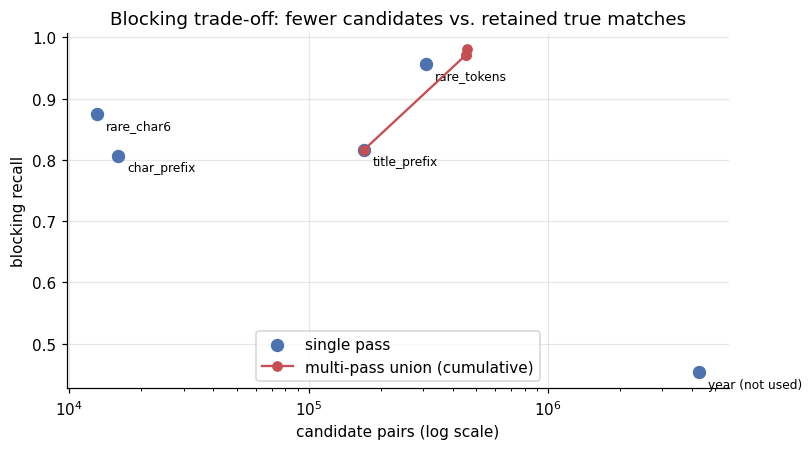

Final candidate set: 459,743 pairs | reduction ratio 99.7265% | blocking recall 98.04%


In [21]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
single = blocking_df[~blocking_df["pass"].str.startswith("∪")]
union_rows = blocking_df[blocking_df["pass"].str.startswith("∪")]
ax.scatter(single.candidates, single.blocking_recall, s=60, color="#4C72B0", label="single pass", zorder=3)
for _, r in single.iterrows():
    ax.annotate(r["pass"], (r.candidates, r.blocking_recall), xytext=(6, -10), textcoords="offset points", fontsize=8)
ax.plot(union_rows.candidates, union_rows.blocking_recall, "o-", color="#C44E52", label="multi-pass union (cumulative)", zorder=3)
ax.set_xscale("log"); ax.set_xlabel("candidate pairs (log scale)"); ax.set_ylabel("blocking recall")
ax.set_title("Blocking trade-off: fewer candidates vs. retained true matches")
ax.legend(loc="lower center"); plt.tight_layout(); save_fig(fig, "blocking_tradeoff"); plt.show()
BM = key_metrics(CAND_KEYS)
print(f"Final candidate set: {BM['candidates']:,} pairs | reduction ratio {BM['reduction_ratio']:.4%} | blocking recall {BM['blocking_recall']:.2%}")

## 10. Similarity features for all candidate pairs

In [22]:
t0 = time.time()
di_c, si_c = keys_to_pairs(CAND_KEYS)
FEAT = compute_features(di_c, si_c)
FEAT["key"] = CAND_KEYS
FEAT["label"] = np.isin(CAND_KEYS, GOLD_KEYS).astype(np.int8)      # used ONLY for evaluation / ML training
FEAT["split"] = dblp.split.to_numpy()[di_c]
MATCH_TIME_FEATURES = time.time() - t0
print(f"computed {FEAT.shape[1]-5} similarity features for {len(FEAT):,} pairs in {MATCH_TIME_FEATURES:.1f}s")
N_GOLD = {s: len(GOLD_SPLIT[s]) for s in ["train", "val", "test"]}
VAL, TEST, TRAIN = (FEAT[FEAT.split == s].reset_index(drop=True) for s in ["val", "test", "train"])
FEAT.describe().T[["mean", "min", "max"]].round(3).iloc[2:]

computed 14 similarity features for 459,743 pairs in 7.5s


,mean,min,max
title_exact,8.000000e-03,0.000,1.0
title_edit,3.070000e-01,0.000,1.0
title_jac,1.380000e-01,0.000,1.0
title_bi,2.380000e-01,0.000,1.0
title_tri,1.400000e-01,0.000,1.0
title_4g,1.100000e-01,0.000,1.0
author_tok,3.200000e-02,0.000,1.0
author_last,1.400000e-02,0.000,1.0
author_best,2.580000e-01,0.000,1.0
venue_exact,4.500000e-02,0.000,1.0


## 11. Mandatory algorithm comparison (Sections 13, 21, 44)

Each measure is evaluated **on its own** as a matcher over the candidate set: the best threshold is chosen on validation, and precision / recall / F1 are reported on test.

In [23]:
def evaluate_single_score(col, df_val=VAL, df_test=TEST, fill=0.0):
    sv = df_val[col].fillna(fill).to_numpy(); st = df_test[col].fillna(fill).to_numpy()
    T, f_val = best_threshold(sv, df_val.label.to_numpy(), N_GOLD["val"])
    m = threshold_sweep(st, df_test.label.to_numpy(), N_GOLD["test"], [T]).iloc[0]
    return {"measure": col, "best threshold (val)": T, "val F1": f_val,
            "test precision": m.precision, "test recall": m.recall, "test F1": m.f1}

# title: combined score with alpha chosen on validation
alpha_rows = []
for a in np.round(np.arange(0, 1.01, 0.1), 2):
    for df in (VAL, TEST):
        df["_tmp"] = a * df.title_edit + (1 - a) * df.title_jac
    alpha_rows.append({"alpha": a, "val best F1": fast_best_f1(VAL._tmp.to_numpy(), VAL.label.to_numpy(), N_GOLD["val"])})
alpha_df = pd.DataFrame(alpha_rows)
ALPHA = float(alpha_df.loc[alpha_df["val best F1"].idxmax(), "alpha"])
for df in (FEAT, VAL, TEST, TRAIN):
    df["title_combined"] = (ALPHA * df.title_edit + (1 - ALPHA) * df.title_jac).astype(np.float32)
print(f"chosen alpha for S_title = alpha*S_edit + (1-alpha)*S_jaccard : {ALPHA}")

title_cmp = pd.DataFrame([evaluate_single_score(c) for c in
                          ["title_exact", "title_edit", "title_jac", "title_bi", "title_tri", "title_4g", "title_combined"]])
title_cmp["measure"] = title_cmp.measure.map({"title_exact": "Exact equality", "title_edit": "Edit similarity",
    "title_jac": "Token Jaccard", "title_bi": "Bigram Jaccard", "title_tri": "Trigram Jaccard",
    "title_4g": "4-gram Jaccard", "title_combined": f"Combined (α={ALPHA})"})
author_cmp = pd.DataFrame([evaluate_single_score(c) for c in ["author_tok", "author_last", "author_best"]])
author_cmp["measure"] = author_cmp.measure.map({"author_tok": "Token Jaccard (all name tokens)",
    "author_last": "Last-name Jaccard", "author_best": "Avg. best-match name edit similarity"})
venue_cmp = pd.DataFrame([evaluate_single_score(c) for c in ["venue_exact", "venue_tok", "venue_tri"]])
venue_cmp["measure"] = venue_cmp.measure.map({"venue_exact": "Exact normalized venue",
    "venue_tok": "Token Jaccard (+acronym)", "venue_tri": "Trigram Jaccard"})
title_cmp.to_csv(f"{OUT_DIR}/compare_title_measures.csv", index=False)
author_cmp.to_csv(f"{OUT_DIR}/compare_author_measures.csv", index=False)
venue_cmp.to_csv(f"{OUT_DIR}/compare_venue_measures.csv", index=False)
print("TITLE measures"); display(title_cmp.round(4))
print("AUTHOR measures (used alone, so F1 is low — authors alone cannot identify a paper)"); display(author_cmp.round(4))
print("VENUE measures"); display(venue_cmp.round(4))

chosen alpha for S_title = alpha*S_edit + (1-alpha)*S_jaccard : 0.6
TITLE measures


,measure,best threshold (val),val F1,test precision,test recall,test F1
0,Exact equality,0.300,0.6060,0.7480,0.5478,0.6325
1,Edit similarity,0.715,0.7694,0.7010,0.8541,0.7700
2,Token Jaccard,0.630,0.7579,0.7297,0.7981,0.7623
3,Bigram Jaccard,0.675,0.7879,0.6921,0.8947,0.7804
4,Trigram Jaccard,0.655,0.7964,0.7228,0.8715,0.7902
5,4-gram Jaccard,0.635,0.7953,0.7308,0.8657,0.7926
6,Combined (α=0.6),0.665,0.7930,0.7485,0.8512,0.7966


AUTHOR measures (used alone, so F1 is low — authors alone cannot identify a paper)


,measure,best threshold (val),val F1,test precision,test recall,test F1
0,Token Jaccard (all name tokens),0.38,0.6664,0.6241,0.7092,0.6640
1,Last-name Jaccard,0.42,0.7048,0.6411,0.7420,0.6879
2,Avg. best-match name edit similarity,0.72,0.7209,0.6296,0.7816,0.6974


VENUE measures


,measure,best threshold (val),val F1,test precision,test recall,test F1
0,Exact normalized venue,0.30,0.1247,0.0843,0.2348,0.1240
1,Token Jaccard (+acronym),0.30,0.1327,0.0701,0.3671,0.1177
2,Trigram Jaccard,0.91,0.1334,0.0759,0.3111,0.1220


**Choosing the attribute measure for the record-level score.** Using an attribute *alone* as a matcher is not the same as its usefulness *inside* the weighted score, so the final choice of author and venue measure is made in the weight search below (validation F1 of the full record score).

## 12. Weighted record-level similarity (Sections 23–24)

$$S(A,B)=\frac{\sum_{k\in K} w_k S_k}{\sum_{k\in K} w_k}$$
where *K* = attributes available for both records (missing values are re-normalized, not treated as 0).

A grid search over weights (step 0.05, $\sum w = 1$) and over the author/venue measure is run on the **validation** split.

In [24]:
def weighted_score(df, w, author_col, venue_col, renormalize=True):
    comps = [(w[0], df.title_combined.to_numpy()), (w[1], df[author_col].to_numpy()),
             (w[2], df[venue_col].to_numpy()), (w[3], df.year.to_numpy())]
    num = np.zeros(len(df)); den = np.zeros(len(df))
    for wk, s in comps:
        ok = ~np.isnan(s)
        num += wk * np.where(ok, s, 0)
        den += wk * (ok if renormalize else 1)
    return (num / np.maximum(den, 1e-12)).astype(np.float32)

grid = [(wt, wa, wv, round(1 - wt - wa - wv, 2))
        for wt in np.round(np.arange(0.30, 0.951, 0.05), 2)
        for wa in np.round(np.arange(0, 0.701, 0.05), 2)
        for wv in np.round(np.arange(0, 0.401, 0.05), 2)
        if 1 - wt - wa - wv > -1e-9]
yv = VAL.label.to_numpy()
t0 = time.time()
search = []
for ac in ["author_tok", "author_last", "author_best"]:
    for vc in ["venue_tok", "venue_tri"]:
        for w in grid:
            search.append({"author": ac, "venue": vc, "w_title": w[0], "w_author": w[1], "w_venue": w[2], "w_year": w[3],
                           "val_best_F1": fast_best_f1(weighted_score(VAL, w, ac, vc), yv, N_GOLD["val"])})
search_df = pd.DataFrame(search).sort_values("val_best_F1", ascending=False).reset_index(drop=True)
print(f"evaluated {len(search_df):,} weight configurations in {time.time()-t0:.1f}s")
best = search_df.iloc[0]
W = tuple(round(float(x), 2) for x in (best.w_title, best.w_author, best.w_venue, best.w_year))
AUTHOR_COL, VENUE_COL = best.author, best.venue
print(f"BEST on validation: weights (title, author, venue, year) = {W}, author measure = {AUTHOR_COL}, venue measure = {VENUE_COL}")
search_df.to_csv(f"{OUT_DIR}/weight_search.csv", index=False)
search_df.head(10).round(4)

evaluated 3,738 weight configurations in 41.6s
BEST on validation: weights (title, author, venue, year) = (0.45, 0.3, 0.05, 0.2), author measure = author_best, venue measure = venue_tok


,author,venue,w_title,w_author,w_venue,w_year,val_best_F1
0,author_best,venue_tok,0.45,0.30,0.05,0.20,0.8779
1,author_best,venue_tri,0.45,0.30,0.05,0.20,0.8779
2,author_best,venue_tri,0.45,0.30,0.00,0.25,0.8760
3,author_best,venue_tok,0.45,0.30,0.00,0.25,0.8760
4,author_best,venue_tri,0.40,0.35,0.05,0.20,0.8760
5,author_best,venue_tok,0.40,0.35,0.05,0.20,0.8753
6,author_best,venue_tok,0.40,0.35,0.10,0.15,0.8743
7,author_best,venue_tri,0.40,0.35,0.10,0.15,0.8741
8,author_best,venue_tok,0.40,0.30,0.10,0.20,0.8728
9,author_best,venue_tri,0.40,0.30,0.05,0.25,0.8722


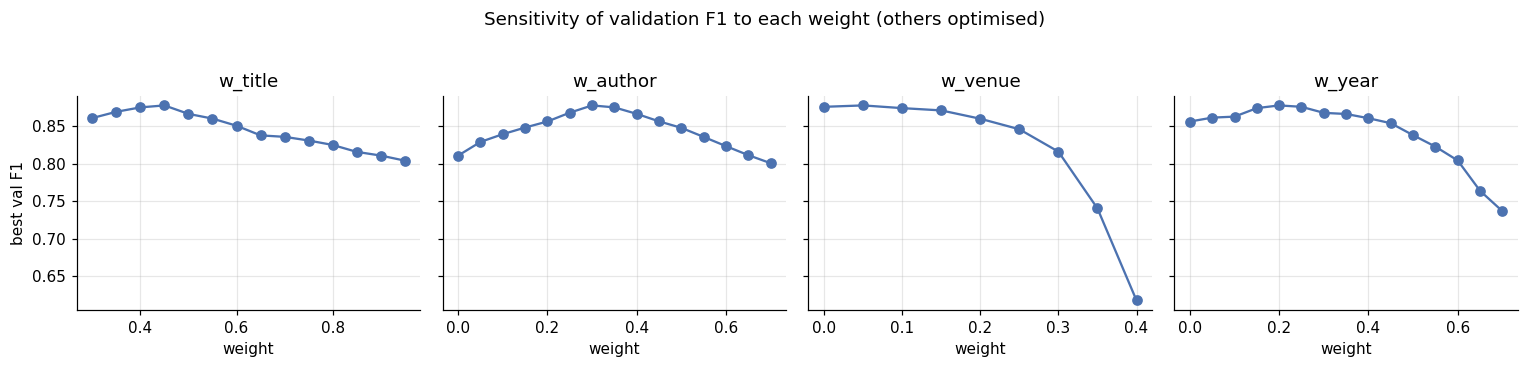

,missing values,val best F1
0,re-normalize weights (Sec. 24),0.8779
1,treat missing as 0,0.8548


In [25]:
# How important is each weight? best achievable validation F1 for each value of one weight
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
sub = search_df[(search_df.author == AUTHOR_COL) & (search_df.venue == VENUE_COL)]
for a, col in zip(ax, ["w_title", "w_author", "w_venue", "w_year"]):
    s = sub.groupby(col).val_best_F1.max()
    a.plot(s.index, s.values, "o-", color="#4C72B0"); a.set_title(col); a.set_xlabel("weight")
ax[0].set_ylabel("best val F1")
fig.suptitle("Sensitivity of validation F1 to each weight (others optimised)", y=1.03)
plt.tight_layout(); save_fig(fig, "weight_sensitivity"); plt.show()

# ablation: missing-value re-normalization vs. treating missing as 0
abl = []
for renorm in (True, False):
    s = weighted_score(VAL, W, AUTHOR_COL, VENUE_COL, renormalize=renorm)
    abl.append({"missing values": "re-normalize weights (Sec. 24)" if renorm else "treat missing as 0",
                "val best F1": fast_best_f1(s, yv, N_GOLD["val"])})
pd.DataFrame(abl).round(4)

## 13. Threshold analysis & confidence bands (Sections 33, 35, 41)

In [26]:
for df in (FEAT, VAL, TEST, TRAIN):
    df["score"] = weighted_score(df, W, AUTHOR_COL, VENUE_COL)

MANDATORY_T = [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
FINE_T = np.round(np.arange(0.40, 0.991, 0.01), 2)
sweep_val = threshold_sweep(VAL.score, VAL.label, N_GOLD["val"], FINE_T)
sweep_test_mand = threshold_sweep(TEST.score, TEST.label, N_GOLD["test"], MANDATORY_T)
THRESHOLD = float(sweep_val.loc[sweep_val.f1.idxmax(), "threshold"])
print(f"Operating threshold chosen on VALIDATION: T = {THRESHOLD}")
sweep_test_mand.to_csv(f"{OUT_DIR}/threshold_sweep_test.csv", index=False)
sweep_val.to_csv(f"{OUT_DIR}/threshold_sweep_val.csv", index=False)
print("Mandatory thresholds on the TEST split:")
sweep_test_mand.round(4)

Operating threshold chosen on VALIDATION: T = 0.65
Mandatory thresholds on the TEST split:


,threshold,TP,FP,FN,precision,recall,f1
0,0.50,1012,678,23,0.5988,0.9778,0.7428
1,0.60,973,296,62,0.7667,0.9401,0.8446
2,0.70,865,71,170,0.9241,0.8357,0.8777
3,0.75,783,42,252,0.9491,0.7565,0.8419
4,0.80,678,31,357,0.9563,0.6551,0.7775
5,0.85,547,26,488,0.9546,0.5285,0.6803
6,0.90,419,25,616,0.9437,0.4048,0.5666
7,0.95,229,4,806,0.9828,0.2213,0.3612


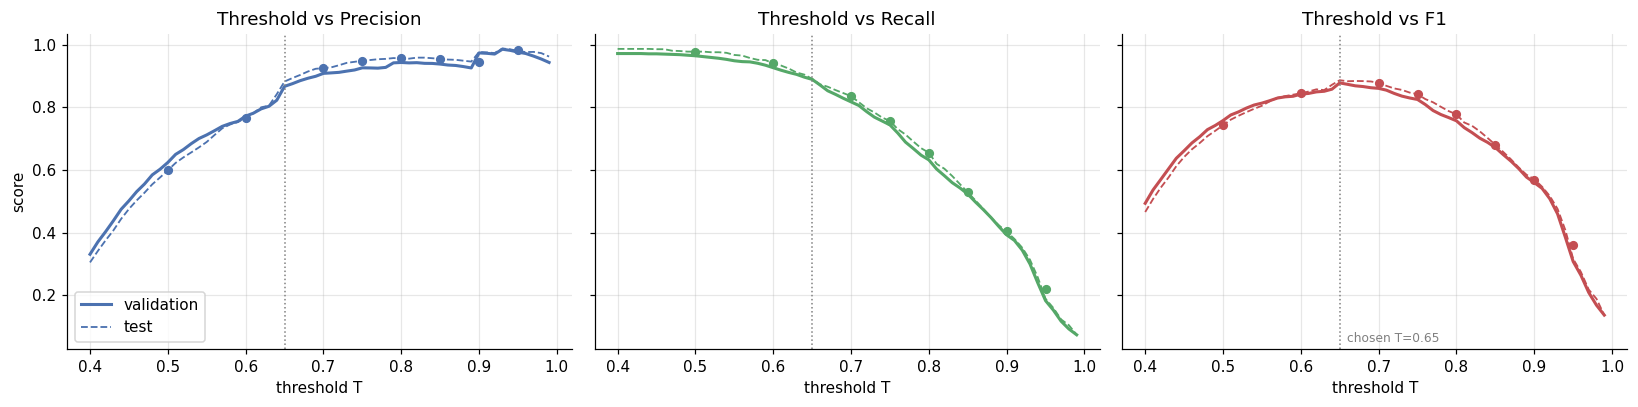

In [27]:
sweep_test_fine = threshold_sweep(TEST.score, TEST.label, N_GOLD["test"], FINE_T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, m, c in zip(ax, ["precision", "recall", "f1"], ["#4C72B0", "#55A868", "#C44E52"]):
    a.plot(sweep_val.threshold, sweep_val[m], color=c, lw=2, label="validation")
    a.plot(sweep_test_fine.threshold, sweep_test_fine[m], color=c, lw=1.2, ls="--", label="test")
    a.scatter(MANDATORY_T, sweep_test_mand[m], color=c, zorder=3, s=25)
    a.axvline(THRESHOLD, color="grey", ls=":", lw=1)
    a.set_title(f"Threshold vs {m.capitalize() if m!='f1' else 'F1'}"); a.set_xlabel("threshold T")
ax[0].set_ylabel("score"); ax[0].legend(loc="lower left")
ax[2].annotate(f"chosen T={THRESHOLD}", (THRESHOLD, 0.05), xytext=(5, 0), textcoords="offset points", fontsize=8, color="grey")
plt.tight_layout(); save_fig(fig, "threshold_curves"); plt.show()

**Confidence bands from data, not guesses.** On the validation split:
- **High-confidence** lower bound $T_{high}$ = smallest threshold whose predictions are ≥ 97 % precise;
- **Likely non-match** upper bound $T_{low}$ = largest threshold below which at most 1 % of the true matches found by blocking fall;
- everything in between goes to **manual review** in the web app.

In [28]:
cand_true_val = VAL.label.sum()
hi = sweep_val[sweep_val.precision >= 0.97].threshold
T_HIGH = float(hi.min()) if len(hi) else 0.95
rel_recall = np.array([(VAL.label[VAL.score >= t]).sum() / cand_true_val for t in FINE_T])
T_LOW = float(FINE_T[rel_recall >= 0.99].max()) if (rel_recall >= 0.99).any() else float(FINE_T.min())
T_HIGH = max(T_HIGH, THRESHOLD); T_LOW = min(T_LOW, THRESHOLD)

def band(s):
    return np.where(s >= T_HIGH, "High confidence", np.where(s >= T_LOW, "Manual review", "Likely non-match"))

for df in (FEAT, VAL, TEST, TRAIN):
    df["band"] = band(df.score.to_numpy())
band_df = (TEST.groupby("band").agg(pairs=("label", "size"), true_matches=("label", "sum"))
           .assign(match_rate=lambda x: (x.true_matches / x.pairs).round(4))
           .reindex(["High confidence", "Manual review", "Likely non-match"]))
print(f"Bands (chosen on validation):  S ≥ {T_HIGH} high confidence | {T_LOW} ≤ S < {T_HIGH} manual review | S < {T_LOW} likely non-match")
print("How the bands behave on the TEST split:")
band_df

Bands (chosen on validation):  S ≥ 0.9 high confidence | 0.49 ≤ S < 0.9 manual review | S < 0.49 likely non-match
How the bands behave on the TEST split:


,pairs,true_matches,match_rate
band,,,
High confidence,444,419,0.9437
Manual review,1313,593,0.4516
Likely non-match,91731,9,0.0001


## 14. Optional ML extension — Logistic Regression & Decision Tree (Sections 36–38)

Feature vector $X = [S_{title}, S_{author}, S_{venue}, S_{year}, TitleLengthRatio]$ plus three missing-value indicators (missing values are set to 0 and flagged, so the model can learn how to treat them).
- Train on the **train** split candidate pairs; keep **all** positives and a reproducible sample of negatives (`random_state=42`, 20 negatives per positive).
- Choose hyper-parameters and the probability threshold on **validation** (full, unsampled).
- Report once on **test**. CPU only, runs in seconds.

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

FEATURE_NAMES = ["S_title", "S_author", "S_venue", "S_year", "TitleLengthRatio", "author_missing", "venue_missing", "year_missing"]
def make_X(df):
    return np.column_stack([df.title_combined, np.nan_to_num(df[AUTHOR_COL]), np.nan_to_num(df[VENUE_COL]),
                            np.nan_to_num(df.year), df.len_ratio, df[AUTHOR_COL].isna(), df[VENUE_COL].isna(),
                            df.year.isna()]).astype(np.float32)

pos = TRAIN[TRAIN.label == 1]; neg = TRAIN[TRAIN.label == 0]
neg_s = neg.sample(min(len(neg), 20 * len(pos)), random_state=SEED)
TR = pd.concat([pos, neg_s]).sample(frac=1, random_state=SEED)
X_tr, y_tr = make_X(TR), TR.label.to_numpy()
X_va, y_va = make_X(VAL), VAL.label.to_numpy()
X_te, y_te = make_X(TEST), TEST.label.to_numpy()
print(f"training pairs: {len(TR):,} ({len(pos):,} positive, {len(neg_s):,} sampled negative of {len(neg):,})")

ml_rows, models = [], {}
for C in [0.01, 0.1, 1, 10]:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000, random_state=SEED)).fit(X_tr, y_tr)
    T, f = best_threshold(m.predict_proba(X_va)[:, 1], y_va, N_GOLD["val"], grid=np.round(np.arange(0.05, 0.996, 0.01), 2))
    ml_rows.append({"model": "Logistic Regression", "param": f"C={C}", "val F1": f, "threshold": T}); models[("LR", C)] = (m, T)
for depth in [3, 4, 5, 6, 8, 10]:
    m = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=SEED).fit(X_tr, y_tr)
    T, f = best_threshold(m.predict_proba(X_va)[:, 1], y_va, N_GOLD["val"], grid=np.round(np.arange(0.05, 0.996, 0.01), 2))
    ml_rows.append({"model": "Decision Tree", "param": f"max_depth={depth}", "val F1": f, "threshold": T}); models[("DT", depth)] = (m, T)
ml_df = pd.DataFrame(ml_rows)
ml_df.round(4)

training pairs: 65,562 (3,122 positive, 62,440 sampled negative of 271,714)


,model,param,val F1,threshold
0,Logistic Regression,C=0.01,0.8806,0.71
1,Logistic Regression,C=0.1,0.8844,0.79
2,Logistic Regression,C=1,0.8844,0.81
3,Logistic Regression,C=10,0.8848,0.81
4,Decision Tree,max_depth=3,0.8818,0.77
5,Decision Tree,max_depth=4,0.8940,0.60
6,Decision Tree,max_depth=5,0.8913,0.85
7,Decision Tree,max_depth=6,0.8887,0.83
8,Decision Tree,max_depth=8,0.8860,0.83
9,Decision Tree,max_depth=10,0.8853,0.83


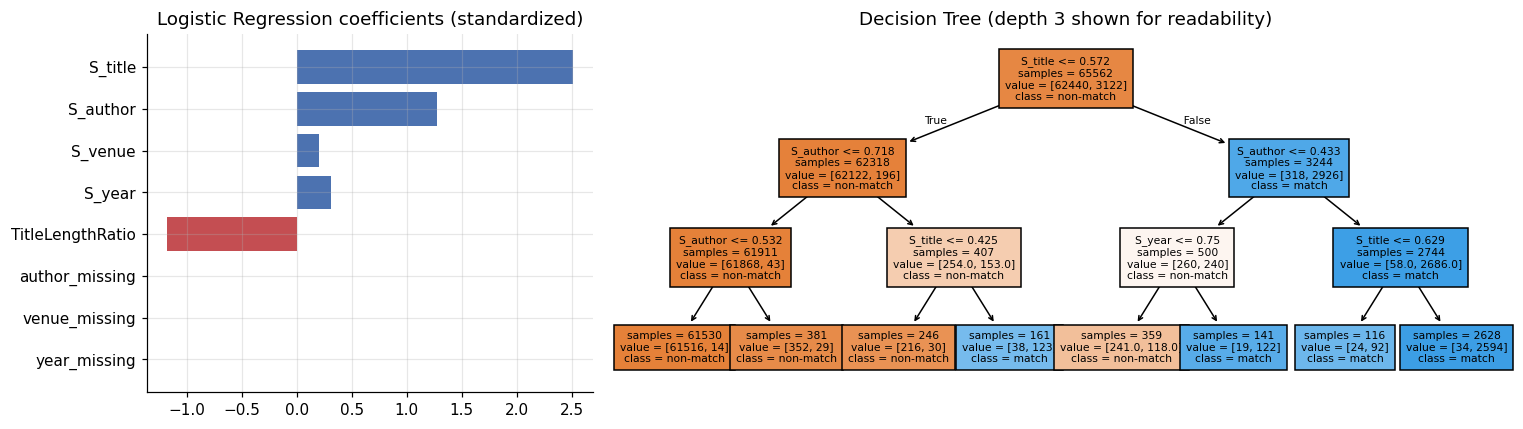

In [30]:
best_lr = ml_df[ml_df.model == "Logistic Regression"].sort_values("val F1").iloc[-1]
best_dt = ml_df[ml_df.model == "Decision Tree"].sort_values("val F1").iloc[-1]
LR_MODEL, LR_T = models[("LR", float(best_lr.param.split("=")[1]))]
DT_MODEL, DT_T = models[("DT", int(best_dt.param.split("=")[1]))]
for df in (FEAT, VAL, TEST):
    X = make_X(df)
    df["lr_prob"] = LR_MODEL.predict_proba(X)[:, 1]
    df["dt_prob"] = DT_MODEL.predict_proba(X)[:, 1]

coef = LR_MODEL[-1].coef_[0]
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2]})
ax[0].barh(FEATURE_NAMES, coef, color=["#4C72B0" if c > 0 else "#C44E52" for c in coef])
ax[0].set_title("Logistic Regression coefficients (standardized)"); ax[0].invert_yaxis()
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEED).fit(X_tr, y_tr)
plot_tree(small_tree, feature_names=FEATURE_NAMES, class_names=["non-match", "match"], filled=True, ax=ax[1], fontsize=7, impurity=False)
ax[1].set_title("Decision Tree (depth 3 shown for readability)")
plt.tight_layout(); save_fig(fig, "ml_models"); plt.show()

## 15. Final method comparison (Section 39)

| Method | What it does |
|---|---|
| Baseline 1 | exact normalized title, all pairs (hash join) |
| Baseline 2 | single fuzzy-title score (edit similarity), **all 168 M pairs, no blocking** |
| Method 3 | weighted multi-attribute similarity, **all 168 M pairs, no blocking** |
| Method 4 | weighted similarity **+ multi-pass blocking** |
| Method 5 | Logistic Regression on blocked candidates (and Decision Tree) |

Methods 2 and 3 are computed brute-force with fast C++/sparse-matrix code in chunks of DBLP records so they fit in Colab memory (about a minute). This lets us measure honestly what blocking costs in recall and saves in work. With the pure-Python scorer the same brute-force run would take the number of hours printed in Section 5.1.

In [31]:
RUN_BRUTE_FORCE = True    # set False to skip (~1–2 min on Colab)

def brute_force(min_keep=0.45, chunk=128):
    """score every DBLP x Scholar pair; keep pairs above min_keep for B2 (title edit) and M3 (weighted)"""
    ac_space = SPACES[AUTHOR_COL] if AUTHOR_COL in SPACES else SPACES["author_last"]
    keep_b2, keep_m3 = [], []
    t0 = time.time()
    for start in range(0, N_D, chunk):
        rows = np.arange(start, min(start + chunk, N_D))
        edit = process.cdist(D_T[rows], S_T, scorer=RFLevenshtein.normalized_similarity, dtype=np.float32, workers=-1)
        tj = SPACES["title_tok"].matrix(rows)
        title = ALPHA * edit + (1 - ALPHA) * np.nan_to_num(tj)
        au = ac_space.matrix(rows); ve = SPACES[VENUE_COL].matrix(rows)
        yr = year_score_vec(D_Y[rows][:, None], S_Y[None, :])
        num = W[0] * title; den = np.full(title.shape, W[0], dtype=np.float32)
        for wk, s in ((W[1], au), (W[2], ve), (W[3], yr)):
            ok = ~np.isnan(s); num += wk * np.where(ok, s, 0); den += wk * ok
        S = num / den
        r, c = np.nonzero(edit >= min_keep); keep_b2.append(np.column_stack([rows[r], c, edit[r, c]]))
        r, c = np.nonzero(S >= min_keep); keep_m3.append(np.column_stack([rows[r], c, S[r, c]]))
    elapsed = time.time() - t0
    to_df = lambda arrs: pd.DataFrame(np.vstack(arrs), columns=["di", "si", "score"]).astype({"di": int, "si": int})
    return to_df(keep_b2), to_df(keep_m3), elapsed

def eval_pairs_df(df, T, split):
    sub = df[(df.score >= T) & (dblp.split.to_numpy()[df.di.to_numpy()] == split)]
    keys = sub.di.to_numpy().astype(np.int64) * N_S + sub.si.to_numpy()
    g = np.array([D_IDX[d] * N_S + S_IDX[s] for d, s in GOLD_SPLIT[split]], dtype=np.int64)
    tp = int(np.isin(keys, g).sum()); fp = len(keys) - tp; fn = len(g) - tp
    p = tp / (tp + fp) if tp + fp else 0; r = tp / len(g)
    return {"TP": tp, "FP": fp, "FN": fn, "precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0}

def tune_on_val(df):
    labels = np.isin(df.di.to_numpy().astype(np.int64) * N_S + df.si.to_numpy(), GOLD_KEYS)
    m = dblp.split.to_numpy()[df.di.to_numpy()] == "val"
    return best_threshold(df.score.to_numpy()[m], labels[m], N_GOLD["val"], grid=np.round(np.arange(0.45, 0.996, 0.01), 2))[0]

comparison = []
b1 = baseline_df[(baseline_df.method == "Exact normalized title") & (baseline_df.split == "test")].iloc[0]
comparison.append({"method": "B1  Exact normalized title", "pairs scored": "hash join", "time_s": t_exact,
                   "threshold": "—", **{k: b1[k] for k in ["TP", "FP", "FN", "precision", "recall", "f1"]}})
if RUN_BRUTE_FORCE:
    B2_DF, M3_DF, BF_TIME = brute_force()
    T2, T3 = tune_on_val(B2_DF), tune_on_val(M3_DF)
    comparison.append({"method": "B2  Fuzzy title (edit sim), no blocking", "pairs scored": f"{P_ALL:,}", "time_s": BF_TIME,
                       "threshold": T2, **eval_pairs_df(B2_DF, T2, "test")})
    comparison.append({"method": "M3  Weighted multi-attribute, no blocking", "pairs scored": f"{P_ALL:,}", "time_s": BF_TIME,
                       "threshold": T3, **eval_pairs_df(M3_DF, T3, "test")})
m4 = threshold_sweep(TEST.score, TEST.label, N_GOLD["test"], [THRESHOLD]).iloc[0]
comparison.append({"method": "M4  Weighted + multi-pass blocking", "pairs scored": f"{len(FEAT):,}",
                   "time_s": BLOCKING_TIME + MATCH_TIME_FEATURES, "threshold": THRESHOLD,
                   **m4[["TP", "FP", "FN", "precision", "recall", "f1"]].to_dict()})
for name, col, T in [("M5  Logistic Regression + blocking", "lr_prob", LR_T), ("M5b Decision Tree + blocking", "dt_prob", DT_T)]:
    m = threshold_sweep(TEST[col], TEST.label, N_GOLD["test"], [T]).iloc[0]
    comparison.append({"method": name, "pairs scored": f"{len(FEAT):,}", "time_s": BLOCKING_TIME + MATCH_TIME_FEATURES,
                       "threshold": T, **m[["TP", "FP", "FN", "precision", "recall", "f1"]].to_dict()})
comparison_df = pd.DataFrame(comparison)
for c in ["TP", "FP", "FN"]:
    comparison_df[c] = comparison_df[c].astype(int)
comparison_df.to_csv(f"{OUT_DIR}/method_comparison.csv", index=False)
print("All numbers are on the untouched TEST split; thresholds were chosen on validation.")
comparison_df.style.format({"time_s": "{:.1f}", "precision": "{:.4f}", "recall": "{:.4f}", "f1": "{:.4f}"})

All numbers are on the untouched TEST split; thresholds were chosen on validation.


,method,pairs scored,time_s,threshold,TP,FP,FN,precision,recall,f1
0,B1 Exact normalized title,hash join,0.1,—,567,191,468,0.7480,0.5478,0.6325
1,"B2 Fuzzy title (edit sim), no blocking","168,112,008",82.4,0.700000,904,422,131,0.6817,0.8734,0.7658
2,"M3 Weighted multi-attribute, no blocking","168,112,008",82.4,0.580000,884,146,151,0.8583,0.8541,0.8562
3,M4 Weighted + multi-pass blocking,"459,743",16.1,0.650000,922,124,113,0.8815,0.8908,0.8861
4,M5 Logistic Regression + blocking,"459,743",16.1,0.810000,905,107,130,0.8943,0.8744,0.8842
5,M5b Decision Tree + blocking,"459,743",16.1,0.600000,913,116,122,0.8873,0.8821,0.8847


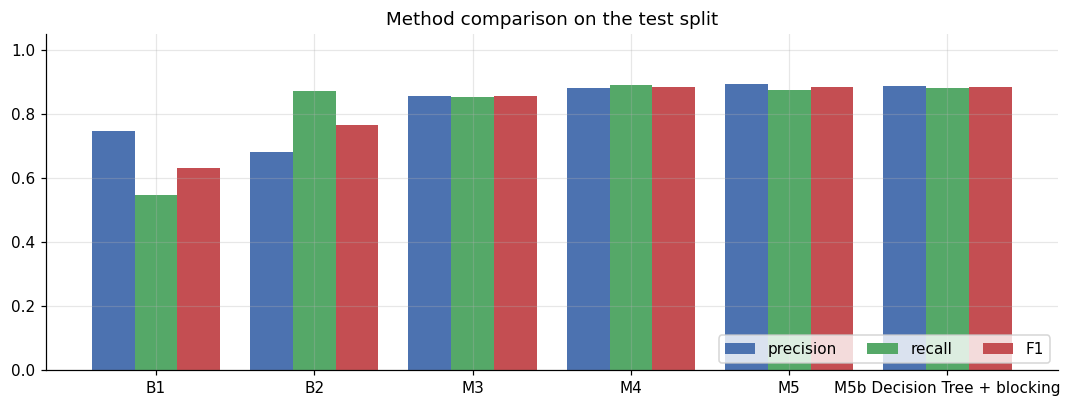

In [32]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(comparison_df)); wbar = 0.27
for k, (m, c) in enumerate(zip(["precision", "recall", "f1"], ["#4C72B0", "#55A868", "#C44E52"])):
    ax.bar(x + (k - 1) * wbar, comparison_df[m], wbar, label=m if m != "f1" else "F1", color=c)
ax.set_xticks(x); ax.set_xticklabels([s.split("  ")[0] for s in comparison_df.method])
ax.set_ylim(0, 1.05); ax.set_title("Method comparison on the test split"); ax.legend(ncol=3, loc="lower right")
plt.tight_layout(); save_fig(fig, "method_comparison"); plt.show()

**How to read the comparison (our run):** on the DBLP–Scholar data, multi-pass blocking scores only about 0.3 % of the 168 M pairs but keeps about 98 % of the gold matches. The blocked pipeline (M4) is *not* worse than the brute-force weighted score (M3). In our run it was slightly better, because blocking also throws away many accidental look-alike pairs before they can become false positives. Weighted multi-attribute scoring beats any single title score mainly through the **author** attribute. Logistic Regression and the Decision Tree add only about 0.5 F1 points over the tuned rule-based score. Check these statements against the numbers printed above before you put them in the report.

## 16. Error analysis — 20 false positives & 20 false negatives (Section 45)

Errors come from Method 4 on the **test** split. False negatives include gold pairs that blocking never produced (`missed by blocking`).
Each error gets **automatic cause tags** from simple rules, which act as a first pass. **Read every row yourself** and correct the `manual_cause` column in the exported CSV, because the problem statement requires manual inspection.

In [33]:
def tag_causes(r):
    c = []
    if r.get("in_candidates") is False:
        c.append("Missed by blocking")
    if pd.isna(r.author_s) or pd.isna(r.author_d): c.append("Missing author")
    if pd.isna(r.venue_s) or pd.isna(r.venue_d): c.append("Missing venue")
    elif not pd.isna(r.S_venue) and r.S_venue < 0.2: c.append("Abbreviated / different venue")
    if pd.isna(r.year_s): c.append("Missing year")
    elif not pd.isna(r.year_d) and r.year_d != r.year_s: c.append("Wrong / different year")
    if len(str(r.title_d).split()) <= 3: c.append("Short generic title")
    if r.S_title >= 0.9 and r.kind == "FP": c.append("Very similar titles")
    if r.kind == "FN" and r.S_title < 0.75:
        if r.title_tri >= 0.6 and r.title_jac < 0.5: c.append("Glued words in Scholar title")
        elif r.len_ratio < 0.7: c.append("Title length mismatch (extra / truncated text)")
        else: c.append("Severe spelling variation")
    if r.kind == "FN" and not pd.isna(r.S_author) and 0 < r.S_author < 0.5: c.append("Different author lists / ordering")
    return "; ".join(c) if c else "Other"

def error_rows(df, kind):
    out = pd.DataFrame({
        "kind": kind, "dblp_id": dblp.id.to_numpy()[df.di], "scholar_id": scholar.id.to_numpy()[df.si],
        "title_d": dblp.title.to_numpy()[df.di], "title_s": scholar.title.to_numpy()[df.si],
        "author_d": dblp.authors.to_numpy()[df.di], "author_s": scholar.authors.to_numpy()[df.si],
        "venue_d": dblp.venue.to_numpy()[df.di], "venue_s": scholar.venue.to_numpy()[df.si],
        "year_d": dblp.year.to_numpy()[df.di], "year_s": scholar.year.to_numpy()[df.si],
        "S_title": df.title_combined.values, "S_author": df[AUTHOR_COL].values, "S_venue": df[VENUE_COL].values,
        "S_year": df.year.values, "score": df.score.values, "title_tri": df.title_tri.values, "title_jac": df.title_jac.values,
        "len_ratio": df.len_ratio.values, "in_candidates": df["in_candidates"].values})
    out["auto_causes"] = out.apply(tag_causes, axis=1)
    out["manual_cause"] = ""
    return out

pred = TEST.score >= THRESHOLD
fp_df = TEST[pred & (TEST.label == 0)].assign(in_candidates=True)
fn_in = TEST[~pred & (TEST.label == 1)].assign(in_candidates=True)
test_gold_keys = np.array([D_IDX[d] * N_S + S_IDX[s] for d, s in GOLD_SPLIT["test"]], dtype=np.int64)
missed = test_gold_keys[~np.isin(test_gold_keys, CAND_KEYS)]
fn_out = compute_features(*keys_to_pairs(missed)) if len(missed) else pd.DataFrame()
if len(fn_out):
    fn_out["title_combined"] = ALPHA * fn_out.title_edit + (1 - ALPHA) * fn_out.title_jac
    fn_out["score"] = weighted_score(fn_out, W, AUTHOR_COL, VENUE_COL); fn_out["in_candidates"] = False
fn_all = pd.concat([fn_in, fn_out], ignore_index=True)
print(f"test errors: {len(fp_df)} false positives | {len(fn_all)} false negatives "
      f"({len(fn_in)} below threshold, {len(fn_out)} missed by blocking)")

FP20 = error_rows(fp_df.sample(min(20, len(fp_df)), random_state=SEED), "FP")
FN20 = error_rows(fn_all.sample(min(20, len(fn_all)), random_state=SEED), "FN")
errors_df = pd.concat([FP20, FN20], ignore_index=True)
errors_df.to_csv(f"{OUT_DIR}/error_analysis_40_cases.csv", index=False)
show_cols = ["kind", "title_d", "title_s", "year_d", "year_s", "S_title", "S_author", "score", "auto_causes"]
display(FP20[show_cols].round(3))
display(FN20[show_cols].round(3))

test errors: 124 false positives | 113 false negatives (99 below threshold, 14 missed by blocking)


,kind,title_d,title_s,year_d,year_s,S_title,S_author,score,auto_causes
0,FP,Editor's Notes,Editor's notes,2000,NaN,1.000,0.273,0.665,Abbreviated / different venue; Missing year; Short generic title; Very simil...
1,FP,Editor's Notes,Editor's notes,1995,NaN,1.000,0.239,0.652,Abbreviated / different venue; Missing year; Short generic title; Very simil...
2,FP,Minimization of Tree Pattern Queries,Efficient algorithms for minimizing tree pattern queries,2001,NaN,0.495,1.000,0.666,Missing year
3,FP,Keynote Address,Keynote Address,1995,NaN,1.000,0.000,0.900,Missing author; Missing venue; Missing year; Short generic title; Very simil...
4,FP,An Ultra Highly Available DBMS,Designing an ultra highly available DBMS,2000,NaN,0.758,0.798,0.725,Abbreviated / different venue; Missing year
5,FP,Book review column,Book Review Column,2003,2003.0,1.000,0.143,0.743,Short generic title; Very similar titles
6,FP,SQL Open Heterogeneous Data Access,SQL table function open architecture and data access middleware,1998,1998.0,0.412,1.000,0.685,Missing venue
7,FP,Editor's Notes,Editor's notes,2002,NaN,1.000,0.333,0.688,Abbreviated / different venue; Missing year; Short generic title; Very simil...
8,FP,Editor's Notes,Editor's Notes,2002,NaN,1.000,0.333,0.688,Abbreviated / different venue; Missing year; Short generic title; Very simil...
9,FP,Book Review Column,Book Review Column,2002,2002.0,1.000,0.250,0.775,Short generic title; Very similar titles


,kind,title_d,title_s,year_d,year_s,S_title,S_author,score,auto_causes
0,FN,Sybase Replication Server,The Sybase Replication Server Project,1994,1993.0,0.755,0.529,0.598,Abbreviated / different venue; Wrong / different year; Short generic title
1,FN,Fast Algorithms for Mining Association Rules in Large Databases,Srikant. R. Fast algorithms for mining association rules,1994,NaN,0.544,0.833,0.618,Abbreviated / different venue; Missing year; Severe spelling variation
2,FN,Storage and Retrieval of XML Data Using Relational Databases,Storage and retrieval of XML data using relational databases,2001,2003.0,1.000,0.000,0.643,Missing author; Missing venue; Wrong / different year
3,FN,The Dangers of Replication and a Solution,"PO'Neil and D. Shasha, 1997. The Dangers of Replication and a Solution",1996,NaN,0.486,0.747,0.553,Abbreviated / different venue; Missing year; Title length mismatch (extra / ...
4,FN,Aurora: A Data Stream Management System,Aurora: a new model and architecture for data stream management,2003,2003.0,0.454,0.633,0.594,Abbreviated / different venue; Title length mismatch (extra / truncated text)
5,FN,XML-Based Information Mediation with MIX,XML-Based Information Mediation with MIXâ?? exhibition program,1999,NaN,0.629,0.749,0.635,Abbreviated / different venue; Missing year; Title length mismatch (extra / ...
6,FN,Spatial Hash-Joins,"Spatial Hash-Joins, ACM SIGMOD Intl",1996,NaN,0.518,0.864,0.615,Abbreviated / different venue; Missing year; Short generic title; Title leng...
7,FN,The Dangers of Replication and a Solution,"p. O'Neil, and D. Shasha,â??The Dangers of Replications and a Solution,â??",1996,NaN,0.446,0.809,0.570,Missing year; Title length mismatch (extra / truncated text)
8,FN,Decision Tables: Scalable Classification Exploring RDBMS Capabilities,Decision tables: Scalable classification exploring RDBMS capabilities [A],2000,NaN,1.000,0.173,0.627,Abbreviated / different venue; Missing year; Different author lists / ordering
9,FN,Data Grid Management Systems,Grid Data Management Systems &amp; Services,2003,2003.0,0.559,0.661,0.650,Abbreviated / different venue; Title length mismatch (extra / truncated text)


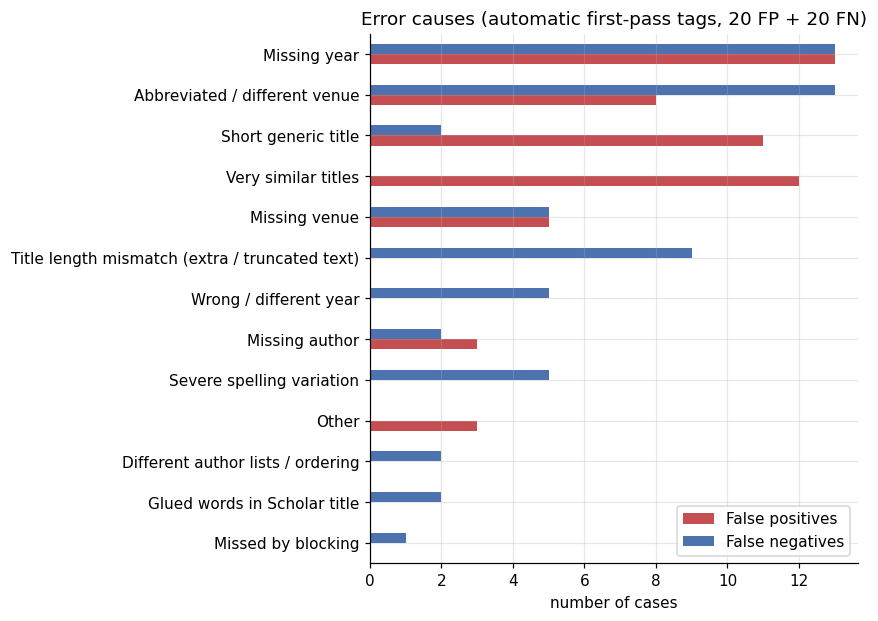

In [34]:
def cause_counts(df):
    return Counter(c for s in df.auto_causes for c in s.split("; "))
cc = pd.DataFrame({"False positives": cause_counts(FP20), "False negatives": cause_counts(FN20)}).fillna(0).astype(int)
cc = cc.loc[cc.sum(1).sort_values().index]
fig, ax = plt.subplots(figsize=(8, 0.35 * len(cc) + 1.2))
cc.plot(kind="barh", ax=ax, color=["#C44E52", "#4C72B0"])
ax.set_title("Error causes (automatic first-pass tags, 20 FP + 20 FN)"); ax.set_xlabel("number of cases")
plt.tight_layout(); save_fig(fig, "error_causes"); plt.show()

## 17. Scalability experiments (Section 43)

The full pipeline (blocking → features → weighted score → threshold) is re-run on 10 %, 25 %, 50 %, 75 % and 100 % of Scholar (reproducible random samples). Precision / recall / F1 are reported on the DBLP test split; blocking recall uses all gold pairs whose Scholar record is in the sample.

In [35]:
scal_rows = []
perm_s = np.random.default_rng(SEED).permutation(N_S)
for frac in [0.10, 0.25, 0.50, 0.75, 1.00]:
    s_rows = np.sort(perm_s[: int(round(frac * N_S))])
    t0 = time.time(); keys, _, _ = run_blocking(s_rows); t_block = time.time() - t0
    t0 = time.time()
    F = compute_features(*keys_to_pairs(keys))
    F["title_combined"] = ALPHA * F.title_edit + (1 - ALPHA) * F.title_jac
    F["score"] = weighted_score(F, W, AUTHOR_COL, VENUE_COL)
    t_match = time.time() - t0
    in_sample = np.isin(GOLD_KEYS % N_S, s_rows)
    g_keys = GOLD_KEYS[in_sample]
    is_test = dblp.split.to_numpy()[keys // N_S] == "test"
    g_test = g_keys[dblp.split.to_numpy()[g_keys // N_S] == "test"]
    pred_keys = keys[(F.score.to_numpy() >= THRESHOLD) & is_test]
    tp = int(np.isin(pred_keys, g_test).sum()); p = tp / max(len(pred_keys), 1); r = tp / max(len(g_test), 1)
    cart = N_D * len(s_rows)
    scal_rows.append({"scholar_fraction": f"{int(frac*100)}%", "scholar_records": len(s_rows), "dblp_records": N_D,
                      "cartesian_pairs": cart, "candidate_pairs": len(keys), "blocking_time_s": t_block,
                      "matching_time_s": t_match, "reduction_ratio": 1 - len(keys) / cart,
                      "blocking_recall": np.isin(g_keys, keys).mean(), "precision": p, "recall": r,
                      "f1": 2 * p * r / (p + r) if p + r else 0,
                      "est_bruteforce_python_h": cart * PY_SEC_PER_PAIR / 3600})
    print(f"{int(frac*100):>3}% done", end=" | ")
scal_df = pd.DataFrame(scal_rows)
scal_df.to_csv(f"{OUT_DIR}/scalability.csv", index=False)
print()
scal_df.style.format({"cartesian_pairs": "{:,}", "candidate_pairs": "{:,}", "blocking_time_s": "{:.2f}", "matching_time_s": "{:.2f}",
                      "reduction_ratio": "{:.5f}", "blocking_recall": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}",
                      "f1": "{:.4f}", "est_bruteforce_python_h": "{:.1f}"})

 10% done |  25% done |  50% done |  75% done | 100% done | 


,scholar_fraction,scholar_records,dblp_records,cartesian_pairs,candidate_pairs,blocking_time_s,matching_time_s,reduction_ratio,blocking_recall,precision,recall,f1,est_bruteforce_python_h
0,10%,6426,2616,"16,810,416","46,840",0.92,0.63,0.99721,0.9874,0.8609,0.8919,0.8761,3.0
1,25%,16066,2616,"42,028,656","114,481",1.70,1.50,0.99728,0.9879,0.8686,0.9084,0.8881,7.4
2,50%,32132,2616,"84,057,312","230,477",4.23,4.55,0.99726,0.9823,0.8752,0.9034,0.8891,14.9
3,75%,48197,2616,"126,083,352","343,481",6.61,4.62,0.99728,0.9799,0.8815,0.9019,0.8916,22.3
4,100%,64263,2616,"168,112,008","459,743",10.28,7.61,0.99727,0.9804,0.8815,0.8908,0.8861,29.7


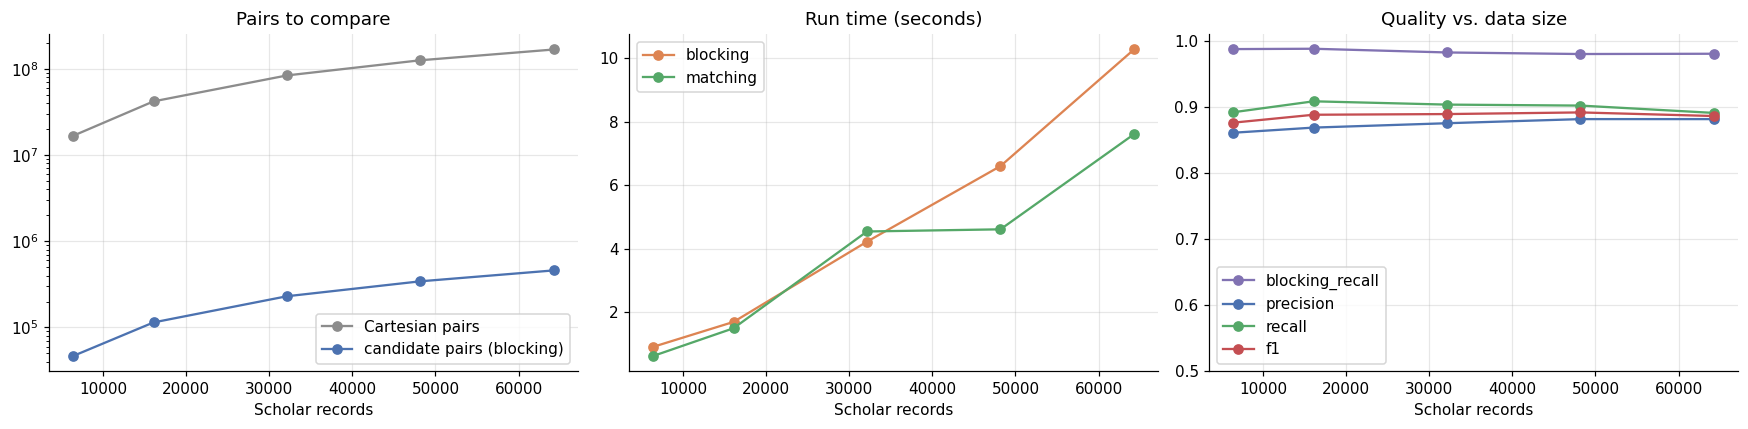

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
xs = scal_df.scholar_records
ax[0].plot(xs, scal_df.cartesian_pairs, "o-", label="Cartesian pairs", color="#8C8C8C")
ax[0].plot(xs, scal_df.candidate_pairs, "o-", label="candidate pairs (blocking)", color="#4C72B0")
ax[0].set_yscale("log"); ax[0].set_title("Pairs to compare"); ax[0].set_xlabel("Scholar records"); ax[0].legend()
ax[1].plot(xs, scal_df.blocking_time_s, "o-", label="blocking", color="#DD8452")
ax[1].plot(xs, scal_df.matching_time_s, "o-", label="matching", color="#55A868")
ax[1].set_title("Run time (seconds)"); ax[1].set_xlabel("Scholar records"); ax[1].legend()
for m, c in [("blocking_recall", "#8172B2"), ("precision", "#4C72B0"), ("recall", "#55A868"), ("f1", "#C44E52")]:
    ax[2].plot(xs, scal_df[m], "o-", label=m, color=c)
ax[2].set_ylim(0.5, 1.01); ax[2].set_title("Quality vs. data size"); ax[2].set_xlabel("Scholar records"); ax[2].legend(loc="lower left")
plt.tight_layout(); save_fig(fig, "scalability"); plt.show()

## 18. Save everything to the relational database (SQLite)

Schema follows Section 9 (updated): `MATCH_RESULT` also stores the split, the confidence band and the ML probability, and a new `REVIEW` table stores human decisions. Student 2 owns the database design, so align the table and column names with theirs if they differ.

In [37]:
con = sqlite3.connect(DB_PATH, check_same_thread=False)
con.executescript("""
DROP TABLE IF EXISTS DBLP_RECORD; DROP TABLE IF EXISTS SCHOLAR_RECORD; DROP TABLE IF EXISTS GOLD_MATCH;
DROP TABLE IF EXISTS CANDIDATE_PAIR; DROP TABLE IF EXISTS MATCH_RESULT; DROP TABLE IF EXISTS EXPERIMENT;
CREATE TABLE DBLP_RECORD   (record_id TEXT PRIMARY KEY, title TEXT, authors TEXT, venue TEXT, year INTEGER, split TEXT);
CREATE TABLE SCHOLAR_RECORD(record_id TEXT PRIMARY KEY, title TEXT, authors TEXT, venue TEXT, year INTEGER);
CREATE TABLE GOLD_MATCH    (dblp_id TEXT REFERENCES DBLP_RECORD, scholar_id TEXT REFERENCES SCHOLAR_RECORD, PRIMARY KEY (dblp_id, scholar_id));
CREATE TABLE CANDIDATE_PAIR(dblp_id TEXT, scholar_id TEXT, blocking_rule TEXT, PRIMARY KEY (dblp_id, scholar_id));
CREATE TABLE MATCH_RESULT  (dblp_id TEXT, scholar_id TEXT, title_similarity REAL, author_similarity REAL,
                            venue_similarity REAL, year_similarity REAL, overall_similarity REAL, lr_probability REAL,
                            prediction INTEGER, band TEXT, split TEXT, PRIMARY KEY (dblp_id, scholar_id));
CREATE TABLE IF NOT EXISTS REVIEW (dblp_id TEXT, scholar_id TEXT, decision TEXT CHECK (decision IN ('Confirm Match','Reject Match','Needs Review')),
                            note TEXT, reviewer TEXT, reviewed_at TEXT, PRIMARY KEY (dblp_id, scholar_id));
CREATE TABLE EXPERIMENT    (name TEXT PRIMARY KEY, result_json TEXT, created_at TEXT);
""")
cols = ["id", "title", "authors", "venue", "year"]
dblp[cols + ["split"]].rename(columns={"id": "record_id"}).to_sql("DBLP_RECORD", con, if_exists="append", index=False)
scholar[cols].rename(columns={"id": "record_id"}).to_sql("SCHOLAR_RECORD", con, if_exists="append", index=False)
gold_df[["dblp_id", "scholar_id"]].to_sql("GOLD_MATCH", con, if_exists="append", index=False)

rule_names = list(PASS_KEYS)
member = np.column_stack([np.isin(CAND_KEYS, PASS_KEYS[n]) for n in rule_names])
rules = np.array([",".join(n for n, m in zip(rule_names, row) if m) for row in member])
DBLP_IDS, SCH_IDS = dblp.id.to_numpy(), scholar.id.to_numpy()
pd.DataFrame({"dblp_id": DBLP_IDS[di_c], "scholar_id": SCH_IDS[si_c], "blocking_rule": rules}).to_sql(
    "CANDIDATE_PAIR", con, if_exists="append", index=False)
FEAT["dblp_id"] = DBLP_IDS[FEAT.di]; FEAT["scholar_id"] = SCH_IDS[FEAT.si]
pd.DataFrame({"dblp_id": FEAT.dblp_id, "scholar_id": FEAT.scholar_id, "title_similarity": FEAT.title_combined,
              "author_similarity": FEAT[AUTHOR_COL], "venue_similarity": FEAT[VENUE_COL], "year_similarity": FEAT.year,
              "overall_similarity": FEAT.score, "lr_probability": FEAT.lr_prob,
              "prediction": (FEAT.score >= THRESHOLD).astype(int), "band": FEAT.band, "split": FEAT.split}).to_sql(
    "MATCH_RESULT", con, if_exists="append", index=False)
con.execute("CREATE INDEX IF NOT EXISTS idx_match_band ON MATCH_RESULT(band, overall_similarity)")
con.execute("CREATE INDEX IF NOT EXISTS idx_match_dblp ON MATCH_RESULT(dblp_id)")

# restore earlier review decisions from Drive (they survive Colab restarts)
if os.path.exists(REVIEW_CSV):
    old = pd.read_csv(REVIEW_CSV).drop_duplicates(["dblp_id", "scholar_id"], keep="last")
    con.executemany("INSERT OR REPLACE INTO REVIEW VALUES (?,?,?,?,?,?)", old[["dblp_id", "scholar_id", "decision", "note", "reviewer", "reviewed_at"]].fillna("").values.tolist())

SUMMARY = {
    "dataset": {"dblp": N_D, "scholar": N_S, "gold": len(GOLD), "cartesian_pairs": P_ALL},
    "blocking": {"candidates": int(len(CAND_KEYS)), "reduction_ratio": BM["reduction_ratio"], "blocking_recall": BM["blocking_recall"],
                 "time_s": BLOCKING_TIME},
    "chosen": {"alpha": ALPHA, "weights_title_author_venue_year": list(map(float, W)), "author_measure": AUTHOR_COL,
               "venue_measure": VENUE_COL, "threshold": THRESHOLD, "band_high": T_HIGH, "band_low": T_LOW},
    "test_results": comparison_df.drop(columns=["pairs scored"]).to_dict(orient="records"),
}
con.execute("INSERT OR REPLACE INTO EXPERIMENT VALUES (?,?,datetime('now'))", ("final_run", json.dumps(SUMMARY, default=float)))
con.commit()
print(pd.read_sql("SELECT name AS tbl FROM sqlite_master WHERE type='table'", con).assign(
    rows=lambda x: [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in x.tbl]))
with open(f"{OUT_DIR}/summary.json", "w") as f:
    json.dump(SUMMARY, f, indent=2, default=float)
if IN_COLAB:
    shutil.copy(DB_PATH, f"{OUT_DIR}/entityguard.db")
    print("database copied to Drive:", f"{OUT_DIR}/entityguard.db")

              tbl    rows
0     DBLP_RECORD    2616
1  SCHOLAR_RECORD   64263
2      GOLD_MATCH    5347
3  CANDIDATE_PAIR  459743
4    MATCH_RESULT  459743
5          REVIEW       0
6      EXPERIMENT       1
database copied to Drive: /content/drive/MyDrive/EntityGuard/outputs/entityguard.db


## 19. Web application — human review interface + dashboard (Sections 40, 46)

The app has the tabs from Section 46: **Dataset Statistics · Blocking · Evaluation · Scalability · Review Pair · Reviews**.

The *Review Pair* tab shows pairs side by side with their similarity scores and the **Confirm Match / Reject Match / Needs Review** buttons. By default it queues the *Manual review* band, most uncertain pairs first. Each decision is written to the `REVIEW` table and appended to `human_reviews.csv` on Drive. The *Reviews* tab compares the human decisions with the gold mapping.

Run the cell, then open the **public URL** (`https://….gradio.live`) it prints. Stop it with the ⏹ button on the cell.

In [46]:
import gradio as gr
from datetime import datetime

REVIEW_POOL = FEAT[["dblp_id", "scholar_id", "di", "si", "title_combined", AUTHOR_COL, VENUE_COL, "year", "score",
                    "lr_prob", "band", "label", "split"]].copy()
REVIEW_POOL["uncertainty"] = (REVIEW_POOL.score - THRESHOLD).abs()
ERROR_KEYS = {"Error analysis: false positives": set(zip(FP20.dblp_id, FP20.scholar_id)),
              "Error analysis: false negatives": set(zip(FN20.dblp_id, FN20.scholar_id))}

def reviewed_set():
    return set(con.execute("SELECT dblp_id, scholar_id FROM REVIEW").fetchall())

def queue(kind):
    done = reviewed_set()
    if kind in ERROR_KEYS:      # may include gold pairs that blocking missed, so build the queue directly
        pairs = sorted(p for p in ERROR_KEYS[kind] if p not in done)
        return pd.DataFrame(pairs, columns=["dblp_id", "scholar_id"]), len(pairs)
    q = REVIEW_POOL[REVIEW_POOL.band == kind]
    q = q.sort_values("uncertainty")
    mask = ~q[["dblp_id", "scholar_id"]].apply(tuple, axis=1).isin(done) if done else np.ones(len(q), bool)
    return q[mask], int(mask.sum())

def fmt(v):
    return "—" if v is None or (isinstance(v, float) and math.isnan(v)) or (v is pd.NA) else str(v)

def pair_card(dblp_id, scholar_id, show_gold=False):
    if dblp_id not in D_IDX or scholar_id not in S_IDX:
        return "**Pair not found.** Check the ids.", ""
    a, b = dblp.iloc[D_IDX[dblp_id]], scholar.iloc[S_IDX[scholar_id]]
    F = compute_features([D_IDX[dblp_id]], [S_IDX[scholar_id]])
    F["title_combined"] = ALPHA * F.title_edit + (1 - ALPHA) * F.title_jac
    s = float(weighted_score(F, W, AUTHOR_COL, VENUE_COL)[0]); f = F.iloc[0]
    lr = float(LR_MODEL.predict_proba(make_X(F))[0, 1])
    bd = band(np.array([s]))[0]
    yr_txt = "— (missing)" if np.isnan(f.year) else f"{f.year:.2f}"
    md = f"""
| | **DBLP record** | **Scholar record** |
|---|---|---|
| **ID** | `{dblp_id}` | `{scholar_id}` |
| **Title** | {fmt(a.title)} | {fmt(b.title)} |
| **Authors** | {fmt(a.authors)} | {fmt(b.authors)} |
| **Venue** | {fmt(a.venue)} | {fmt(b.venue)} |
| **Year** | {fmt(a.year)} | {fmt(b.year)} |
"""
    sc = f"""
| Similarity | Score |
|---|---|
| Title Similarity | **{f.title_combined:.2f}** |
| Author Similarity | **{fmt(round(float(f[AUTHOR_COL]), 2)) if not np.isnan(f[AUTHOR_COL]) else '— (missing)'}** |
| Venue Similarity | **{fmt(round(float(f[VENUE_COL]), 2)) if not np.isnan(f[VENUE_COL]) else '— (missing)'}** |
| Year Similarity | **{yr_txt}** |
| **Overall Score** | **{s:.2f}** (threshold {THRESHOLD}) |
| Logistic Regression P(match) | {lr:.2f} |
| Confidence band | {bd} |
"""
    if show_gold:
        sc += f"\n**Gold mapping (evaluation only):** {'✅ true match' if (dblp_id, scholar_id) in GOLD else '❌ not a match'}"
    prev = con.execute("SELECT decision, note FROM REVIEW WHERE dblp_id=? AND scholar_id=?", (dblp_id, scholar_id)).fetchone()
    if prev:
        sc += f"\n\n*Already reviewed:* **{prev[0]}** {('— ' + prev[1]) if prev[1] else ''}"
    return md, sc

def next_pair(kind, show_gold):
    q, n = queue(kind)
    if not len(q):
        return "🎉 Nothing left to review in this queue.", "", "", "", f"0 pairs left in '{kind}'"
    r = q.iloc[0]
    md, sc = pair_card(r.dblp_id, r.scholar_id, show_gold)
    return md, sc, r.dblp_id, r.scholar_id, f"{n:,} unreviewed pairs left in '{kind}'"

def decide(decision, dblp_id, scholar_id, note, reviewer, kind, show_gold):
    if dblp_id and scholar_id:
        ts = datetime.now().isoformat(timespec="seconds")
        row = (dblp_id, scholar_id, decision, note or "", reviewer or "student3", ts)
        con.execute("INSERT OR REPLACE INTO REVIEW VALUES (?,?,?,?,?,?)", row); con.commit()
        pd.DataFrame([row], columns=["dblp_id", "scholar_id", "decision", "note", "reviewer", "reviewed_at"]).to_csv(
            REVIEW_CSV, mode="a", header=not os.path.exists(REVIEW_CSV), index=False)
    return (*next_pair(kind, show_gold), "")

def lookup(dblp_id, scholar_id, show_gold):
    md, sc = pair_card(dblp_id.strip(), scholar_id.strip(), show_gold)
    return md, sc, dblp_id.strip(), scholar_id.strip()

def reviews_table():
    r = pd.read_sql("SELECT * FROM REVIEW ORDER BY reviewed_at DESC", con)
    if not len(r):
        return r, "No reviews yet."
    r["gold"] = [(d, s) in GOLD for d, s in zip(r.dblp_id, r.scholar_id)]
    dec = r[r.decision != "Needs Review"]
    agree = ((dec.decision == "Confirm Match") == dec.gold).mean() if len(dec) else float("nan")
    msg = (f"**{len(r)}** reviews · Confirm {int((r.decision=='Confirm Match').sum())} · Reject {int((r.decision=='Reject Match').sum())} · "
           f"Needs review {int((r.decision=='Needs Review').sum())}  \nAgreement of human decisions with the gold mapping: **{agree:.1%}**")
    return r, msg

def candidate_search(text):
    text = (text or "").strip().lower()
    if not text:
        return pd.DataFrame()
    hit = dblp[dblp.title.str.lower().str.contains(re.escape(text), na=False) | (dblp.id.str.lower() == text)].head(5)
    res = REVIEW_POOL[REVIEW_POOL.dblp_id.isin(hit.id)].sort_values("score", ascending=False).head(30)
    return pd.DataFrame({"dblp_id": res.dblp_id, "scholar_id": res.scholar_id,
                         "DBLP title": dblp.title.to_numpy()[res.di], "Scholar title": scholar.title.to_numpy()[res.si],
                         "score": res.score.round(3), "band": res.band})

def table(df, digits=4):
    return df.round(digits).reset_index() if df.index.name or not isinstance(df.index, pd.RangeIndex) else df.round(digits)

with gr.Blocks(title="EntityGuard") as demo:
    gr.Markdown(f"# 🛡️ EntityGuard\nEntity resolution between **DBLP** ({N_D:,}) and **Google Scholar** ({N_S:,}) · "
                f"{P_ALL:,} possible pairs → **{len(CAND_KEYS):,}** candidates after blocking")
    with gr.Tab("Dataset Statistics"):
        gr.Dataframe(stats_df.reset_index().rename(columns={"index": "statistic"}).astype(str), label="Profile")
        gr.Image(f"{OUT_DIR}/year_distribution.png", label="Years", show_label=False)
        gr.Dataframe(venues_df.astype(str), label="Most common venues")
    with gr.Tab("Blocking"):
        gr.Markdown(f"**Reduction ratio {BM['reduction_ratio']:.4%}** · **Blocking recall {BM['blocking_recall']:.2%}** · "
                    f"blocking time {BLOCKING_TIME:.1f}s")
        gr.Dataframe(blocking_df.round(5).astype(str))
        gr.Image(f"{OUT_DIR}/blocking_tradeoff.png", show_label=False)
    with gr.Tab("Evaluation"):
        gr.Markdown(f"Chosen on validation: weights (title, author, venue, year) = **{W}**, α = **{ALPHA}**, "
                    f"threshold **T = {THRESHOLD}**, bands **{T_LOW} / {T_HIGH}**. All metrics below are on the test split.")
        gr.Dataframe(comparison_df.round(4).astype(str), label="Method comparison")
        gr.Image(f"{OUT_DIR}/method_comparison.png", show_label=False)
        gr.Image(f"{OUT_DIR}/threshold_curves.png", show_label=False)
        gr.Dataframe(sweep_test_mand.round(4).astype(str), label="Mandatory thresholds (test)")
        gr.Dataframe(title_cmp.round(4).astype(str), label="Title similarity measures")
        gr.Image(f"{OUT_DIR}/error_causes.png", show_label=False)
    with gr.Tab("Scalability"):
        gr.Dataframe(scal_df.round(4).astype(str))
        gr.Image(f"{OUT_DIR}/scalability.png", show_label=False)
    with gr.Tab("Review Pair"):
        with gr.Row():
            kind = gr.Dropdown(["Manual review", "High confidence", "Likely non-match",
                                "Error analysis: false positives", "Error analysis: false negatives"],
                               value="Manual review", label="Review queue")
            show_gold = gr.Checkbox(False, label="Show gold label (evaluation only)")
            reviewer = gr.Textbox("student3", label="Reviewer")
        status = gr.Markdown()
        gr.HTML("<style>.eg-card table td:first-child, .eg-card table th:first-child {white-space: nowrap;}</style>")
        with gr.Row():
            rec_md = gr.Markdown(elem_classes=["eg-card"])
            score_md = gr.Markdown(elem_classes=["eg-card"])
        cur_d, cur_s = gr.Textbox(visible=False), gr.Textbox(visible=False)
        note = gr.Textbox(label="Note (optional)", placeholder="e.g. different edition / journal version")
        with gr.Row():
            b_yes = gr.Button("✅ Confirm Match", variant="primary")
            b_no = gr.Button("❌ Reject Match", variant="stop")
            b_maybe = gr.Button("🤔 Needs Review")
            b_skip = gr.Button("⏭ Next pair")
        with gr.Accordion("Look up any pair / search candidates", open=False):
            with gr.Row():
                q_d = gr.Textbox(label="DBLP id"); q_s = gr.Textbox(label="Scholar id")
            b_look = gr.Button("Show pair")
            q_text = gr.Textbox(label="Search DBLP title or id → its candidate pairs")
            cand_out = gr.Dataframe()
        outs = [rec_md, score_md, cur_d, cur_s, status]
        b_skip.click(next_pair, [kind, show_gold], outs)
        kind.change(next_pair, [kind, show_gold], outs)
        def make_decider(dec):
            def handler(d, s, n, r, k, g):
                return decide(dec, d, s, n, r, k, g)
            return handler
        for btn, dec in [(b_yes, "Confirm Match"), (b_no, "Reject Match"), (b_maybe, "Needs Review")]:
            btn.click(make_decider(dec), [cur_d, cur_s, note, reviewer, kind, show_gold], outs + [note])
        b_look.click(lookup, [q_d, q_s, show_gold], [rec_md, score_md, cur_d, cur_s])
        q_text.submit(candidate_search, q_text, cand_out)
        demo.load(next_pair, [kind, show_gold], outs)
    with gr.Tab("Reviews"):
        rev_msg = gr.Markdown(); rev_tbl = gr.Dataframe()
        gr.Button("Refresh").click(reviews_table, None, [rev_tbl, rev_msg])
        demo.load(reviews_table, None, [rev_tbl, rev_msg])

# smoke test of the app's callbacks (read-only, no review is written)
_md, _sc, _d, _s, _st = next_pair("Manual review", False)
assert "DBLP record" in _md and "Overall Score" in _sc and _d in D_IDX
assert "Gold mapping" in pair_card(_d, _s, show_gold=True)[1]
assert len(candidate_search("data cube")) > 0
reviews_table()
print("✅ app callbacks work:", _st)

LAUNCH_APP = IN_COLAB or os.environ.get("EG_LAUNCH") == "1"
if LAUNCH_APP:
    demo.launch(share=IN_COLAB, debug=False)
else:
    print("App built (launch skipped outside Colab).")

✅ app callbacks work: 6,414 unreviewed pairs left in 'Manual review'
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9127f96b65665513c9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 20. (Optional) REST API backend — FastAPI (Section 47)

If your professor wants a real backend, this cell serves the API from Section 47, with the Gradio app mounted at `/ui`. In Colab it runs in a background thread, and the printed URL opens it (it uses Colab's own proxy, so it works only while this notebook is open). Interactive API docs are at `/docs`.

In [39]:
RUN_API = False   # set True to start the API

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

api = FastAPI(title="EntityGuard API")

def json_safe(obj):
    """replace NaN / numpy types so responses are valid JSON"""
    if isinstance(obj, dict):
        return {k: json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [json_safe(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        return None if math.isnan(obj) else float(obj)
    return obj

def rec(df, i):
    r = df.iloc[i]
    return {"record_id": r.id, "title": r.title, "authors": r.authors, "venue": r.venue,
            "year": None if pd.isna(r.year) else int(r.year)}

@api.get("/records/dblp")
def get_dblp(offset: int = 0, limit: int = 20):
    return [rec(dblp, i) for i in range(offset, min(offset + limit, N_D))]

@api.get("/records/scholar")
def get_scholar(offset: int = 0, limit: int = 20):
    return [rec(scholar, i) for i in range(offset, min(offset + limit, N_S))]

@api.post("/blocking/run")
def api_blocking(scholar_fraction: float = 1.0):
    s_rows = np.sort(np.random.default_rng(SEED).permutation(N_S)[: int(round(scholar_fraction * N_S))])
    t0 = time.time(); keys, passes, _ = run_blocking(s_rows)
    g = GOLD_KEYS[np.isin(GOLD_KEYS % N_S, s_rows)]
    return {"candidates": int(len(keys)), "per_pass": {k: int(len(v)) for k, v in passes.items()},
            "reduction_ratio": 1 - len(keys) / (N_D * len(s_rows)), "blocking_recall": float(np.isin(g, keys).mean()),
            "seconds": round(time.time() - t0, 2)}

@api.post("/matching/run")
def api_matching(threshold: float = THRESHOLD):
    pred = FEAT.score >= threshold
    return json_safe({"threshold": threshold, "predicted_matches": int(pred.sum()),
            "test": prf(zip(FEAT.dblp_id[pred & (FEAT.split == "test")], FEAT.scholar_id[pred & (FEAT.split == "test")]), GOLD_SPLIT["test"])})

@api.get("/matches")
def api_matches(band_name: str = "High confidence", limit: int = 50):
    r = pd.read_sql("SELECT * FROM MATCH_RESULT WHERE band=? ORDER BY overall_similarity DESC LIMIT ?", con, params=(band_name, limit))
    return json_safe(r.to_dict(orient="records"))

@api.get("/pair/{dblp_id:path}/{scholar_id}")
def api_pair(dblp_id: str, scholar_id: str):
    if dblp_id not in D_IDX or scholar_id not in S_IDX:
        raise HTTPException(404, "pair not found")
    F = compute_features([D_IDX[dblp_id]], [S_IDX[scholar_id]])
    F["title_combined"] = ALPHA * F.title_edit + (1 - ALPHA) * F.title_jac
    s = float(weighted_score(F, W, AUTHOR_COL, VENUE_COL)[0])
    clean = lambda v: None if pd.isna(v) else float(v)
    return {"dblp": rec(dblp, D_IDX[dblp_id]), "scholar": rec(scholar, S_IDX[scholar_id]),
            "title_similarity": clean(F.title_combined[0]), "author_similarity": clean(F[AUTHOR_COL][0]),
            "venue_similarity": clean(F[VENUE_COL][0]), "year_similarity": clean(F.year[0]),
            "overall_similarity": s, "band": str(band(np.array([s]))[0]), "prediction": int(s >= THRESHOLD)}

class Review(BaseModel):
    dblp_id: str
    scholar_id: str
    decision: str
    note: str = ""
    reviewer: str = "api"

@api.post("/review")
def api_review(r: Review):
    if r.decision not in ("Confirm Match", "Reject Match", "Needs Review"):
        raise HTTPException(400, "decision must be Confirm Match / Reject Match / Needs Review")
    row = (r.dblp_id, r.scholar_id, r.decision, r.note, r.reviewer, datetime.now().isoformat(timespec="seconds"))
    con.execute("INSERT OR REPLACE INTO REVIEW VALUES (?,?,?,?,?,?)", row); con.commit()
    return {"saved": True}

@api.get("/evaluation")
def api_evaluation():
    return json_safe(SUMMARY)

api = gr.mount_gradio_app(api, demo, path="/ui")

if RUN_API:
    import threading, uvicorn
    threading.Thread(target=lambda: uvicorn.run(api, host="0.0.0.0", port=8000, log_level="warning"), daemon=True).start()
    time.sleep(3)
    if IN_COLAB:
        from google.colab.output import eval_js
        print("API docs :", eval_js("google.colab.kernel.proxyPort(8000)") + "docs")
        print("Web app  :", eval_js("google.colab.kernel.proxyPort(8000)") + "ui")
    else:
        print("API running at http://localhost:8000/docs")

In [40]:
# automated API tests (run without starting a server)
from fastapi.testclient import TestClient
client = TestClient(api)
assert client.get("/records/dblp?limit=2").status_code == 200
_d, _s = next(iter(GOLD))
_r = client.get(f"/pair/{_d}/{_s}").json(); assert 0 <= _r["overall_similarity"] <= 1
assert client.get("/evaluation").json()["dataset"]["gold"] == len(GOLD)
assert client.post("/review", json={"dblp_id": "x", "scholar_id": "y", "decision": "bad"}).status_code == 400
assert len(client.get("/matches?limit=3").json()) <= 3
assert client.post("/matching/run").json()["test"]["f1"] > 0
assert client.post("/blocking/run?scholar_fraction=0.1").json()["candidates"] > 0
assert client.post("/review", json={"dblp_id": _d, "scholar_id": _s, "decision": "Confirm Match", "reviewer": "api-test"}).json()["saved"]
con.execute("DELETE FROM REVIEW WHERE reviewer='api-test'"); con.commit()      # remove the test row
print("✅ API tests passed")

✅ API tests passed


In [52]:
import pandas as pd
from datetime import datetime

# 1. Grab 50 unreviewed borderline pairs from the Manual review band
done = set(con.execute("SELECT dblp_id, scholar_id FROM REVIEW").fetchall())
pool = FEAT[FEAT["band"] == "Manual review"].copy()
pool["uncertainty"] = (pool["score"] - THRESHOLD).abs()
pool = pool.sort_values("uncertainty")
pool = pool[~pool[["dblp_id", "scholar_id"]].apply(tuple, axis=1).isin(done)].head(50)

print(f"Loaded {len(pool)} borderline pairs for review.\nType 'y' for Confirm Match, 'n' for Reject Match, or 'q' to stop early:\n")

count = 0
for idx, row in pool.iterrows():
    count += 1
    d = dblp.iloc[int(row["di"])]
    s = scholar.iloc[int(row["si"])]
    print("=" * 70)
    print(f"[{count}/50] Score: {row['score']:.3f} | DBLP: {d['title']} ({d['authors']}, {d['year']})")
    print(f"                        | SCHL: {s['title']} ({s['authors']}, {s['year']})")
    ans = input("Match? (y/n/q): ").strip().lower()
    if ans == 'q':
        break
    decision = "Confirm Match" if ans == 'y' else "Reject Match"
    con.execute("INSERT OR REPLACE INTO REVIEW VALUES (?, ?, ?, ?, ?, ?)",
                (row["dblp_id"], row["scholar_id"], decision, "student3", "", datetime.now().isoformat()))

con.commit()

# 2. Save to human_reviews.csv & compute gold agreement
reviews_df = pd.read_sql("SELECT * FROM REVIEW", con)
reviews_df.to_csv(f"{OUT_DIR}/human_reviews.csv", index=False)

merged = reviews_df.merge(FEAT[["dblp_id", "scholar_id", "label"]], on=["dblp_id", "scholar_id"])
merged["human_match"] = (merged["decision"] == "Confirm Match").astype(int)
agreement = (merged["human_match"] == merged["label"]).mean() * 100
print(f"\nSaved {len(reviews_df)} reviews to human_reviews.csv!")
print(f"Agreement with Gold Mapping: {agreement:.2f}%")

Loaded 50 borderline pairs for review.
Type 'y' for Confirm Match, 'n' for Reject Match, or 'q' to stop early:

[1/50] Score: 0.651 | DBLP: Business-to-business interactions: issues and enabling technologies (B Medjahed, B Benatallah, A Bouguettaya, A Ngu, A Elmagarmid, 2003)
                        | SCHL: Business-to-business interactions: issues and enabling technologies; VLDB Volume 12 Number 1; 2003;   (B Medjahed, B Benatallah, A Bouguettaya, AHH Ngu,  , <NA>)
Match? (y/n/q): y
[2/50] Score: 0.652 | DBLP: The Aditi Deductive Database System (J Vaghani, K Ramamohanarao, D Kemp, Z Somogyi, P Stuckey, T Leask, J Harland, 1994)
                        | SCHL: Design Overview of the Aditi Deductive Database System (J Vaghani, K Ramamohanarao, DB Kemp, Z Somogyi, PJ , <NA>)
Match? (y/n/q): n
[3/50] Score: 0.648 | DBLP: On Random Sampling over Joins (S Chaudhuri, R Motwani, V Narasayya, 1999)
                        | SCHL: Using Random Sampling for Histogram Construction (S Chaudhuri, 

## 21. Results summary (copy into the report)

In [41]:
best_row = comparison_df.loc[comparison_df.f1.idxmax()]
m4row = comparison_df[comparison_df.method.str.startswith("M4")].iloc[0]
b1row = comparison_df.iloc[0]
lines = [
    f"Search space: {P_ALL:,} cross-source pairs ({N_D:,} DBLP × {N_S:,} Scholar), {len(GOLD):,} gold matches.",
    f"Multi-pass blocking produced {len(CAND_KEYS):,} candidates: reduction ratio {BM['reduction_ratio']:.4%}, "
    f"blocking recall {BM['blocking_recall']:.2%}, in {BLOCKING_TIME:.1f}s.",
    f"Year blocking alone would give {year_cands:,} pairs with only {year_hits/len(GOLD):.1%} recall (54% of Scholar has no year).",
    f"Validation chose α={ALPHA}, weights (title, author, venue, year)={W}, author measure '{AUTHOR_COL}', venue measure '{VENUE_COL}', T={THRESHOLD}.",
    f"Test F1: exact-title baseline {b1row.f1:.3f} → weighted + blocking {m4row.f1:.3f} "
    f"(precision {m4row.precision:.3f}, recall {m4row.recall:.3f}).",
    f"Best method on test: {' '.join(best_row.method.split())} with F1 {best_row.f1:.3f}.",
    f"Confidence bands: S ≥ {T_HIGH} high confidence, {T_LOW}–{T_HIGH} manual review, < {T_LOW} likely non-match.",
    f"A pure-Python scorer would need ≈ {PY_SEC_PER_PAIR*P_ALL/3600:.1f} h for all pairs; blocking + matching took "
    f"{BLOCKING_TIME + MATCH_TIME_FEATURES:.0f}s.",
]
if RUN_BRUTE_FORCE:
    m3row = comparison_df[comparison_df.method.str.startswith("M3")].iloc[0]
    lines.append(f"Without blocking (M3) the same weighted score reached F1 {m3row.f1:.3f} (recall {m3row.recall:.3f}); "
                 f"with blocking (M4) only {len(CAND_KEYS)/P_ALL:.2%} of the pairs are scored and recall changes by "
                 f"{(m4row.recall - m3row.recall)*100:+.1f} points.")
print("\n".join("• " + l for l in lines))
with open(f"{OUT_DIR}/results_summary.txt", "w") as f:
    f.write("\n".join(lines))
print("\nAll outputs saved in:", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

• Search space: 168,112,008 cross-source pairs (2,616 DBLP × 64,263 Scholar), 5,347 gold matches.
• Multi-pass blocking produced 459,743 candidates: reduction ratio 99.7265%, blocking recall 98.04%, in 8.5s.
• Year blocking alone would give 4,267,488 pairs with only 45.3% recall (54% of Scholar has no year).
• Validation chose α=0.6, weights (title, author, venue, year)=(0.45, 0.3, 0.05, 0.2), author measure 'author_best', venue measure 'venue_tok', T=0.65.
• Test F1: exact-title baseline 0.632 → weighted + blocking 0.886 (precision 0.881, recall 0.891).
• Best method on test: M4 Weighted + multi-pass blocking with F1 0.886.
• Confidence bands: S ≥ 0.9 high confidence, 0.49–0.9 manual review, < 0.49 likely non-match.
• A pure-Python scorer would need ≈ 29.7 h for all pairs; blocking + matching took 16s.
• Without blocking (M3) the same weighted score reached F1 0.856 (recall 0.854); with blocking (M4) only 0.27% of the pairs are scored and recall changes by +3.7 points.

All outputs sa

## 22. What to do next (Student 3 checklist)

1. **Error analysis is not finished until you read the 40 cases.** Open `outputs/error_analysis_40_cases.csv`, check every row, fill in the `manual_cause` column, and write 1–2 paragraphs on the patterns you see (e.g. generic titles like *Editor's Notes*, citation text glued onto Scholar titles, papers that have both a conference and a journal version).
2. **Review some pairs in the app** (e.g. 50 from the *Manual review* queue) and report the agreement with the gold mapping from the *Reviews* tab.
3. **Integrate with teammates:** replace the 🔁 cells (Sections 4, 5, 9) with imports of Student 1's and Student 2's modules from the GitHub repo, then re-run everything. If their numbers differ, compare them with the reference versions here.
4. **Report:** use `outputs/results_summary.txt`, the CSV tables and the PNG plots in `outputs/` for the evaluation, ML, error-analysis and scalability chapters.
5. **Git:** commit this notebook into `experiments/`, and move the evaluation functions (Section 6) into `src/evaluation/` with their tests in `tests/`.